# 14 · Modelos con y sin régimen: walk-forward

En los notebooks 11–13 examinamos modelos con CPCV. Ahora construiremos una referencia que respete el orden cronológico: **aprender del pasado y predecir el año siguiente**. Primero construiremos la referencia y después mediremos qué aporta añadir información del entorno.

- **M0:** frecuencia de éxitos del entrenamiento de cada año.
- **M1:** logística L2 con retorno del último mes y momentum 12–1.
- **M2:** la misma logística, añadiendo volatilidad, retorno de 24 meses y drawdown de 12 meses.
- **M3:** M2 más la interacción mercado bajista × volatilidad.

«Sin régimen» es una definición operativa: estas dos variables describen las señales y también pueden reflejar indirectamente el mercado. M2 añade las tres variables directas de régimen. M3 estudia la interacción prevista, después se examinan las tres retiradas individuales de M2.

**Entradas:** tablas de 01 → 02 → 07 → 08 y el entorno `.venv` con el extra `models`. La sección CPCV necesita además las tablas del notebook 10, la parte walk-forward es independiente de ellas. No necesitas repetir el 09 ni 11–13. El diseño, motivado por la guía del 15 de noviembre, está en [el protocolo](../docs/validacion_walk_forward.md). Se ha definido después de conocer los experimentos anteriores.
La última parte evalúa los mismos seis candidatos con CPCV como robustez. Conserva su propio resumen y muestra también 1950–1989 para alinear los meses objetivo con la prueba cronológica.

Las secciones 19–22 traducen las predicciones cronológicas a cuentas continuas con umbral fijo mayor que 0,5, y las comparan con las referencias económicas. Pueden ejecutarse por separado sin recalcular modelos.

Las secciones 23–25 incorporan random forest con los mismos candidatos y calendario, sin volver a ajustar la logística. Sus comprobaciones se mantienen separadas de las ya realizadas para el modelo lineal.


## 1. Un calendario que avanza año a año

El desarrollo sigue siendo 1927–1989. Para disponer de historia inicial, empezamos las pruebas en 1950. Aprendemos con la historia anterior y mantenemos los coeficientes fijos durante los doce meses de ese año. Al año siguiente ampliamos el entrenamiento y volvemos a ajustar. Son cuarenta periodos anuales de prueba, hasta 1989.

Aplicamos una purga de un mes objetivo anterior. Para probar 1950 usamos etiquetas hasta noviembre de 1949, diciembre de 1949 queda excluido. El calendario se define antes de retirar meses sin señal o sin características. Los meses futuros nunca entrenan ese ajuste. Como no hay entrenamiento posterior a su prueba, el embargo posterior de CPCV no elimina meses aquí.

La normalización causal de las características sí se actualiza con la historia anterior a cada nueva observación. Mantener los coeficientes durante el año no implica congelar en enero esa preparación.

,split_id,test_year,strategy,train_calendar_months,train_first_target,train_last_target,train_examples,train_positive,train_classes,purge_calendar_months,validation_calendar_months,no_signal_months,excluded_active_months,validation_examples,validation_positive,validation_classes
0,1,1950,momentum,275,1933-06,1949-04,110,68,2,1,12,0,0,12,10,2
1,1,1950,reversal,275,1930-08,1949-11,230,86,2,1,12,0,0,12,2,2
78,40,1989,momentum,743,1933-06,1987-12,429,251,2,1,12,0,0,12,8,2
79,40,1989,reversal,743,1930-08,1988-11,697,260,2,1,12,0,0,12,3,2


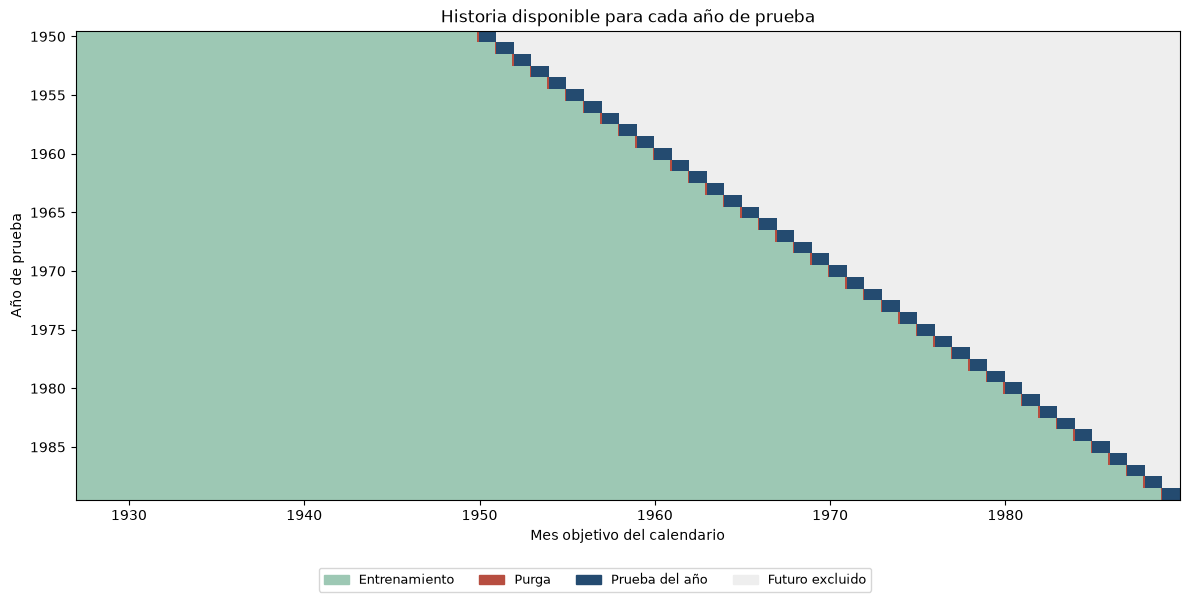

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display

from tfm.data import project_root, save_result
from tfm.walk_forward import (FIRST_TEST_YEAR, LAST_TEST_YEAR, SIGNAL_COLUMNS,
    build_walk_forward_splits, load_walk_forward_inputs, summarize_walk_forward, run_walk_forward)

ROOT = project_root()
ejemplos, _, _ = load_walk_forward_inputs(ROOT)
particiones = build_walk_forward_splits()
cobertura = summarize_walk_forward(ejemplos, particiones)
display(cobertura.loc[cobertura.test_year.isin([FIRST_TEST_YEAR, LAST_TEST_YEAR])])

colores = {'train': ('Entrenamiento', '#9dc8b4'), 'purge': ('Purga', '#b74e40'),
           'validation': ('Prueba del año', '#244b70'), 'future': ('Futuro excluido', '#eeeeee')}
matriz = particiones.pivot(index='test_year', columns='target_period', values='role')
codigos = {nombre: i for i, nombre in enumerate(colores)}
fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(matriz.replace(codigos).to_numpy(dtype=int), aspect='auto', interpolation='nearest',
          cmap=ListedColormap([color for _, color in colores.values()]), vmin=-.5, vmax=3.5)
x = [i for i, mes in enumerate(matriz.columns) if mes.endswith('-01') and int(mes[:4]) % 10 == 0]
y = list(range(0, len(matriz), 5))
ax.set_xticks(x, [matriz.columns[i][:4] for i in x])
ax.set_yticks(y, [matriz.index[i] for i in y])
ax.set(title='Historia disponible para cada año de prueba', xlabel='Mes objetivo del calendario', ylabel='Año de prueba')
fig.legend(handles=[Patch(color=color, label=nombre) for nombre, color in colores.values()],
           loc='lower center', ncol=4, fontsize=9)
fig.tight_layout(rect=(0, .06, 1, 1))
plt.show()

## 2. Qué ejemplos usamos y qué aprende M1

Una etiqueta indica si la operación aislada de la regla, neta de costes y dividendos aproximados, superó al efectivo. Solo tienen etiqueta las señales activas. Un mes sin operación no es un fallo del filtro y no recibe probabilidad cero.

Conservamos la muestra común de los experimentos anteriores: las diez características preparadas deben estar disponibles tras su calentamiento. M1 solo recibe **dos columnas explícitas**: `z_price_return_1m` y `z_momentum_12_1`. Las restantes no se utilizan para predecir. Así las comparaciones posteriores tendrán las mismas fechas, en lugar de ampliar la muestra de cada modelo por separado.

Usamos la misma logística regularizada del 11, con C=1, sin ponderar clases ni buscar parámetros. Las dos reglas se ajustan por separado. Los años sin señales permanecen en la cobertura. Si solo hay una clase de prueba, la log-loss se puede calcular y el AUC no.

In [2]:
print('Predictores de M1:', SIGNAL_COLUMNS)
display(cobertura.groupby('strategy').agg(
    ejemplos_iniciales=('train_examples', 'min'),
    ejemplos_prueba=('validation_examples', 'sum'),
    minimo_anual=('validation_examples', 'min'),
    maximo_anual=('validation_examples', 'max')))
display(cobertura.loc[cobertura.validation_classes.lt(2),
    ['test_year', 'strategy', 'validation_calendar_months', 'no_signal_months',
     'excluded_active_months', 'validation_examples', 'validation_classes']])

Predictores de M1: ['z_price_return_1m', 'z_momentum_12_1']


,ejemplos_iniciales,ejemplos_prueba,minimo_anual,maximo_anual
strategy,,,,
momentum,110,331,0,12
reversal,230,479,11,12


,test_year,strategy,validation_calendar_months,no_signal_months,excluded_active_months,validation_examples,validation_classes
8,1954,momentum,12,3,0,9,1
9,1954,reversal,12,0,0,12,1
16,1958,momentum,12,8,0,4,1
20,1960,momentum,12,9,0,3,1
40,1970,momentum,12,12,0,0,0
48,1974,momentum,12,12,0,0,0
54,1977,momentum,12,9,0,3,1
64,1982,momentum,12,10,0,2,1
76,1988,momentum,12,11,0,1,1


## 3. Ajustar con el pasado y predecir una sola vez

M0 asigna a cada ejemplo del año la proporción de etiquetas positivas de su entrenamiento. M1 estima una probabilidad a partir de las dos características. Ninguno utiliza las etiquetas del año probado para ajustarse.

A diferencia del resumen de CPCV, cada ejemplo recibe **una única predicción cronológica** de cada modelo. No se promedian cinco modelos ni se cuentan repetidamente los mismos resultados. Si un ajuste no es estimable, sus probabilidades quedan ausentes, no se eliminan esos meses para mejorar el resumen.

In [3]:
def mostrar_progreso(completadas, total):
    if completadas == 1 or completadas % 5 == 0:
        print(f'Años evaluados: {completadas}/{total}', flush=True)

tablas, informe = run_walk_forward(ROOT, progress=mostrar_progreso)
resumen = tablas['walk_forward_summary']
predicciones = tablas['walk_forward_predictions']
metricas = tablas['walk_forward_metrics']
coeficientes = tablas['walk_forward_coefficients']
print('Estado del recorrido:', informe['experiment_status'])
display(resumen[['test_year', 'strategy', 'train_first_target', 'train_last_target',
                'train_examples', 'validation_examples', 'train_classes', 'validation_classes', 'status']])

Años evaluados: 1/40
Años evaluados: 5/40
Años evaluados: 10/40
Años evaluados: 15/40
Años evaluados: 20/40
Años evaluados: 25/40
Años evaluados: 30/40
Años evaluados: 35/40
Años evaluados: 40/40
Estado del recorrido: completed


,test_year,strategy,train_first_target,train_last_target,train_examples,validation_examples,train_classes,validation_classes,status
0,1950,momentum,1933-06,1949-04,110,12,2,2,completed
1,1950,reversal,1930-08,1949-11,230,12,2,2,completed
2,1951,momentum,1933-06,1950-11,122,12,2,2,completed
3,1951,reversal,1930-08,1950-11,242,12,2,2,completed
4,1952,momentum,1933-06,1951-11,134,12,2,2,completed
...,...,...,...,...,...,...,...,...,...
75,1987,reversal,1930-08,1986-11,673,12,2,2,completed
76,1988,momentum,1933-06,1987-11,428,1,2,1,completed
77,1988,reversal,1930-08,1987-11,685,12,2,2,completed
78,1989,momentum,1933-06,1987-12,429,12,2,2,completed


## 4. Leer los resultados

**AUC** describe si las etiquetas favorables reciben probabilidades más altas que las desfavorables. **Log-loss** penaliza probabilidades equivocadas, especialmente las muy seguras. Menor log-loss es favorable, mayor AUC indica mejor ordenación. Ninguna mide por sí sola rentabilidad.

El resumen principal (`pooled`) reúne las predicciones de prueba de los cuarenta años por regla y calcula la métrica una sola vez. No es una media de las AUC anuales. M0 tiene una probabilidad constante dentro de cada año, pero puede cambiar al reentrenarse: su AUC reunida puede diferir de 0,5.

Mostramos también cada año. `single_class` significa que no podemos calcular AUC porque todas las etiquetas son iguales, `no_examples`, que no hubo ejemplos. Estos años permanecen en las tablas. Si faltase una predicción necesaria, el resumen correspondiente quedaría no disponible.

In [4]:
display(metricas.loc[metricas.aggregation.eq('pooled'),
    ['strategy', 'model', 'examples', 'positive', 'negative', 'log_loss', 'auc', 'status', 'auc_status']])
anuales = metricas.loc[metricas.aggregation.eq('year')]
display(anuales[['test_year', 'strategy', 'model', 'examples', 'log_loss', 'auc', 'status', 'auc_status']])
display(anuales.loc[anuales.model.eq('M1')].groupby(['strategy', 'auc_status']).size().rename('Años').reset_index())

,strategy,model,examples,positive,negative,log_loss,auc,status,auc_status
160,momentum,M0,331,191,140,0.684939,0.497251,completed,available
161,momentum,M1,331,191,140,0.669000,0.595625,completed,available
162,reversal,M0,479,178,301,0.661412,0.416244,completed,available
163,reversal,M1,479,178,301,0.644959,0.630296,completed,available


,test_year,strategy,model,examples,log_loss,auc,status,auc_status
0,1950,momentum,M0,12,0.561279,0.500000,completed,available
1,1950,momentum,M1,12,0.547068,0.650000,completed,available
2,1950,reversal,M0,12,0.554177,0.500000,completed,available
3,1950,reversal,M1,12,0.498429,0.950000,completed,available
4,1951,momentum,M0,12,0.637322,0.500000,completed,available
...,...,...,...,...,...,...,...,...
155,1988,reversal,M1,12,0.804425,0.628571,completed,available
156,1989,momentum,M0,12,0.650560,0.500000,completed,available
157,1989,momentum,M1,12,0.651841,0.500000,completed,available
158,1989,reversal,M0,12,0.596665,0.500000,completed,available


,strategy,auc_status,Años
0,momentum,available,32
1,momentum,no_examples,2
2,momentum,single_class,6
3,reversal,available,39
4,reversal,single_class,1


## 5. Ver las probabilidades a lo largo del tiempo

Las líneas muestran las estimaciones de M0 y M1. Los puntos permiten ver también los meses aislados. Los huecos son meses sin ejemplo utilizable: no los rellenamos ni conectamos mediante interpolación. Una probabilidad alta significa que el modelo considera más probable superar al efectivo según nuestra etiqueta, no representa el tamaño de una ganancia ni una recomendación de inversión.

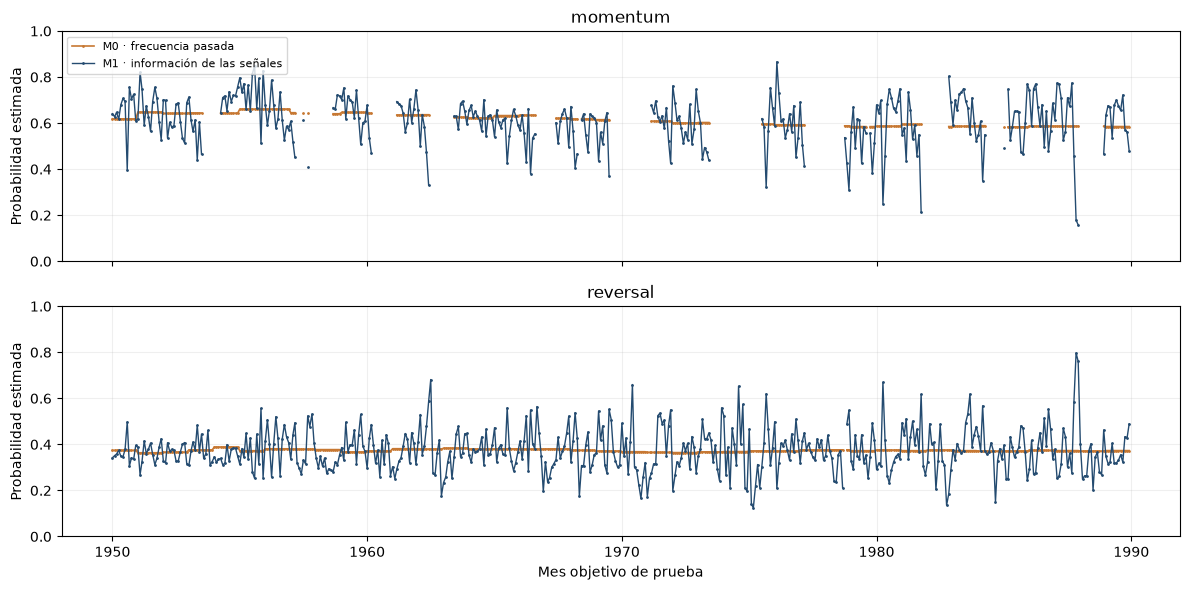

In [5]:
import matplotlib.dates as mdates

meses_prueba = pd.period_range(f'{FIRST_TEST_YEAR}-01', f'{LAST_TEST_YEAR}-12', freq='M').astype(str)
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, regla in zip(axes, ('momentum', 'reversal')):
    serie = predicciones.loc[predicciones.strategy.eq(regla)].set_index('target_period').reindex(meses_prueba)
    fechas = pd.PeriodIndex(serie.index, freq='M').to_timestamp()
    ax.plot(fechas, serie.probability_naive, label='M0 · frecuencia pasada', color='#c77832', linewidth=1.2, marker='.', markersize=2)
    ax.plot(fechas, serie.probability_logistic, label='M1 · información de las señales', color='#244b70', linewidth=1, marker='.', markersize=2)
    ax.set(title=regla, ylabel='Probabilidad estimada', ylim=(0, 1))
    ax.grid(alpha=.2)
axes[0].legend(loc='upper left', fontsize=8)
axes[-1].set_xlabel('Mes objetivo de prueba')
axes[-1].xaxis.set_major_locator(mdates.YearLocator(10))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.tight_layout()
plt.show()

## 6. Guardar la referencia M0/M1

Esta primera parte establece y guarda la referencia para estudiar qué aporta el entorno. La sección siguiente añade M2 con las mismas fechas, ejemplos y parámetros. No seleccionamos variables ni umbrales de operación. Las sombras de la logística de diez características no validan automáticamente estas variantes.

El orden temporal evita entrenar con resultados posteriores al año de prueba. Sin embargo, seguimos usando precios medios mensuales de Shiller, dividendos interpolados y versiones actuales de las fuentes. La purga no certifica sus fechas históricas de publicación. Es una aproximación retrospectiva, no acredita operaciones ejecutables ni disponibilidad point-in-time. El periodo desde 1990 permanece reservado.

La siguiente celda guarda las cinco tablas de referencia con sus JSON. Es necesario publicarlas antes de ejecutar M2. Repetir su publicación retira las comparaciones de régimen anteriores, que deberán recalcularse. El historial del intento está en `outputs/experiments/walk_forward_trials.jsonl`. Si falla el guardado, repite la celda completa. Antes del commit, limpia las salidas y guarda.

Referencia: guía del tutor del 15 de noviembre de 2026, apartado 5, pp. 19–21. La adaptación, el calendario y los supuestos están en [el protocolo](../docs/validacion_walk_forward.md). Se reutilizan las metodologías y referencias de preparación, etiquetado y logística ya documentadas en el proyecto.

In [6]:
guardados = []
for nombre, tabla in tablas.items():
    salida = save_result(ROOT, nombre, tabla, informe)
    guardados.append({'Tabla': nombre + '.parquet', 'Filas': salida['rows']})
display(pd.DataFrame(guardados))
print('Historial:', informe['trial_log'])
print('Evaluación pendiente:', informe['skill_gate_status'])

,Tabla,Filas
0,walk_forward_splits.parquet,30240
1,walk_forward_summary.parquet,80
2,walk_forward_predictions.parquet,810
3,walk_forward_metrics.parquet,164
4,walk_forward_coefficients.parquet,240


Historial: outputs/experiments/walk_forward_trials.jsonl
Evaluación pendiente: pending_regime_comparisons_shadows_and_economic_evaluation


## 7. Qué información añade M2

Ahora planteamos una comparación concreta: ¿la logística mejora al conocer también las condiciones del mercado? M2 conserva las dos entradas de M1 y añade tres variables ya construidas en el notebook 07:

- **Volatilidad de 12 meses:** cuánto han variado los retornos recientes.
- **Retorno de 24 meses:** si el mercado venía subiendo o cayendo y con qué magnitud.
- **Drawdown de 12 meses:** distancia del precio al máximo de esa ventana.

Puede verse como comparar dos decisiones con el mismo historial de señales: una dispone de esa información básica y la otra conoce también el entorno. Todo lo demás permanece igual: logística L2 C=1, ejemplos, etiquetas, años, purga y transformación causal.

Las cinco columnas están fijadas por el protocolo. No se escogen según el resultado de M2, no se usa todavía Clustered MDA y la interacción mercado bajista × volatilidad se estudia por separado en la sección de M3. Esta comparación mide la aportación del **conjunto de tres variables**, no demuestra qué parte corresponde a cada una.

In [7]:
from tfm.walk_forward import REGIME_COLUMNS, M2_COLUMNS, run_walk_forward_regime

print('M1 · información de las señales:', SIGNAL_COLUMNS)
print('M2 · variables de régimen añadidas:', REGIME_COLUMNS)
print('Total de predictores de M2:', len(M2_COLUMNS))

tablas_regimen, informe_regimen = run_walk_forward_regime(ROOT, progress=mostrar_progreso)
comparacion_regimen = tablas_regimen['walk_forward_regime_comparison']
metricas_regimen = tablas_regimen['walk_forward_regime_metrics']
predicciones_regimen = tablas_regimen['walk_forward_regime_predictions']
print('Estado del recorrido M2:', informe_regimen['experiment_status'])
display(pd.DataFrame(informe_regimen['diagnostics'])[
    ['test_year', 'strategy', 'train_examples', 'validation_examples', 'train_positive', 'iterations', 'status']])

M1 · información de las señales: ['z_price_return_1m', 'z_momentum_12_1']
M2 · variables de régimen añadidas: ['z_price_volatility_12m', 'z_market_return_24m', 'z_drawdown_12m']
Total de predictores de M2: 5
Años evaluados: 1/40
Años evaluados: 5/40
Años evaluados: 10/40
Años evaluados: 15/40
Años evaluados: 20/40
Años evaluados: 25/40
Años evaluados: 30/40
Años evaluados: 35/40
Años evaluados: 40/40
Estado del recorrido M2: completed


,test_year,strategy,train_examples,validation_examples,train_positive,iterations,status
0,1950,momentum,110,12,68,15,completed
1,1950,reversal,230,12,86,16,completed
2,1951,momentum,122,12,79,17,completed
3,1951,reversal,242,12,88,18,completed
4,1952,momentum,134,12,86,17,completed
...,...,...,...,...,...,...,...
75,1987,reversal,673,12,251,17,completed
76,1988,momentum,428,1,251,16,completed
77,1988,reversal,685,12,254,14,completed
78,1989,momentum,429,12,251,16,completed


## 8. Comparar los mismos ejemplos

La tabla calcula **AUC de M2 menos AUC de M1**. Una diferencia positiva indica que añadir el régimen mejora la ordenación de las etiquetas. También calcula **log-loss de M1 menos log-loss de M2**, para que una cifra positiva indique mejora en ambos casos. Son diferencias de métricas, no porcentajes de rentabilidad.

La comparación principal reúne una predicción de cada modelo por ejemplo. Por separado, conservamos todos los años. Si en un año hay una sola clase, no se puede medir su mejora de AUC, aunque sí su diferencia de log-loss. Si falta una predicción necesaria, la comparación correspondiente queda no disponible.

La estabilidad exige una mayoría estricta de los cuarenta años previstos: al menos veintiuno con mejora de AUC. Los años sin AUC estimable permanecen en ese total y no se cuentan como favorables. Se muestra también cuántos pudieron evaluarse. Estos años no son ensayos independientes y algunos contienen pocos ejemplos.
En el gráfico, verde indica mejora y rojo empeoramiento. Una diferencia exactamente cero no produce una barra visible, la cruz gris identifica los años cuyo AUC no puede calcularse.


,strategy,examples,auc_m1,auc_m2,auc_improvement,log_loss_m1,log_loss_m2,log_loss_improvement,comparison_status
80,momentum,331,0.595625,0.594764,-0.000860,0.669000,0.673069,-0.004069,available
81,reversal,479,0.630296,0.635839,0.005543,0.644959,0.644421,0.000539,available


,strategy,expected_years,auc_available_years,auc_improved_years,auc_worsened_years,auc_tied_years,auc_unavailable_years,majority_required,meets_majority
0,momentum,40,32,10,9,13,8,21,False
1,reversal,40,39,17,7,15,1,21,False


,test_year,strategy,examples,auc_m1,auc_m2,auc_improvement,log_loss_m1,log_loss_m2,log_loss_improvement,comparison_status,auc_improved
0,1950,momentum,12,0.650000,0.500000,-0.150000,0.547068,0.548475,-0.001407,available,False
1,1950,reversal,12,0.950000,0.950000,0.000000,0.498429,0.494315,0.004114,available,False
2,1951,momentum,12,0.406250,0.437500,0.031250,0.665097,0.669549,-0.004452,available,True
3,1951,reversal,12,0.833333,0.861111,0.027778,0.679809,0.688571,-0.008761,available,True
4,1952,momentum,12,0.500000,0.500000,0.000000,0.639045,0.630964,0.008081,available,False
...,...,...,...,...,...,...,...,...,...,...,...
75,1987,reversal,12,0.370370,0.407407,0.037037,0.808226,0.896718,-0.088493,available,True
76,1988,momentum,1,NaN,NaN,NaN,0.761229,0.732465,0.028764,single_class,<NA>
77,1988,reversal,12,0.628571,0.571429,-0.057143,0.804425,0.770694,0.033732,available,False
78,1989,momentum,12,0.500000,0.531250,0.031250,0.651841,0.676931,-0.025090,available,True


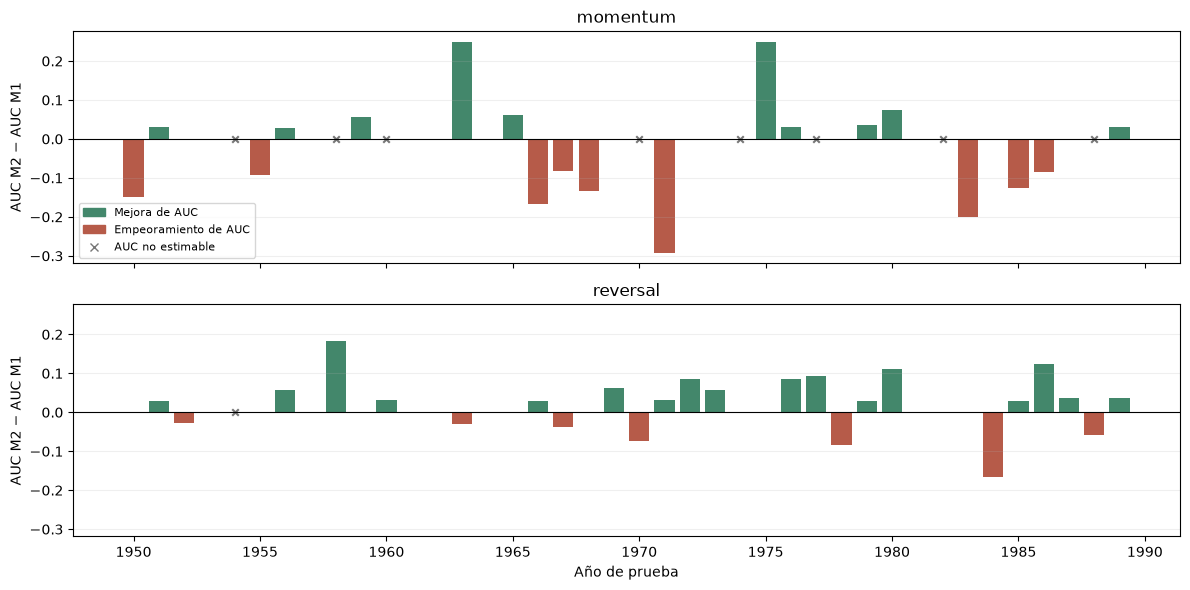

In [8]:
from matplotlib.lines import Line2D

columnas_comparacion = ['strategy', 'examples', 'auc_m1', 'auc_m2', 'auc_improvement',
    'log_loss_m1', 'log_loss_m2', 'log_loss_improvement', 'comparison_status']
display(comparacion_regimen.loc[comparacion_regimen.aggregation.eq('pooled'), columnas_comparacion])
display(pd.DataFrame(informe_regimen['stability']))
display(comparacion_regimen.loc[comparacion_regimen.aggregation.eq('year'),
    ['test_year', *columnas_comparacion, 'auc_improved']])

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, regla in zip(axes, ('momentum', 'reversal')):
    datos = comparacion_regimen.loc[comparacion_regimen.aggregation.eq('year') & comparacion_regimen.strategy.eq(regla)]
    cambio = datos.auc_improvement.to_numpy(dtype=float)
    ax.bar(datos.test_year.to_numpy(dtype=int), cambio,
           color=np.where(cambio > 0, '#43876b', '#b65b49'), label='Diferencia de AUC')
    sin_auc = datos.loc[datos.auc_improvement.isna(), 'test_year'].to_numpy(dtype=int)
    ax.scatter(sin_auc, np.zeros(len(sin_auc)), marker='x', color='#777777', s=22, label='AUC no estimable')
    ax.axhline(0, color='black', linewidth=.8)
    ax.set(title=regla, ylabel='AUC M2 − AUC M1')
    ax.grid(axis='y', alpha=.2)
axes[0].legend(handles=[Patch(color='#43876b', label='Mejora de AUC'),
    Patch(color='#b65b49', label='Empeoramiento de AUC'),
    Line2D([0], [0], marker='x', color='#777777', linestyle='None', label='AUC no estimable')], fontsize=8)
axes[-1].set_xlabel('Año de prueba')
fig.tight_layout()
plt.show()

## 9. Qué podemos concluir en este punto

Una mejora global permite describir una aportación predictiva provisional del bloque de régimen. Su aceptación requiere todavía las comprobaciones previstas: comparación equivalente en CPCV, sombras específicas, estabilidad y Sharpe neto frente al modelo sin régimen y a las referencias. Tampoco una mejora de clasificación garantiza que las operaciones aceptadas ganen más dinero.

Si M2 empeora o no mejora en suficientes años, se documenta el resultado sin cambiar ventanas, variables o parámetros para favorecerlo. A continuación se estudia M3 con la interacción ya prevista. Las retiradas individuales se muestran en la última parte. La selección interna y la evaluación económica siguen pendientes. El periodo desde 1990 permanece reservado. Siguen vigentes las limitaciones de precios medios mensuales y fuentes reconstruidas.

La siguiente celda guarda cuatro tablas adicionales, vinculadas al intento concreto de M0/M1 que se ha leído. M2 solo añade un candidato por regla, los cuarenta años no son cuarenta configuraciones. Su historial comparte `outputs/experiments/walk_forward_trials.jsonl`, distinguiendo las variantes. Si falla la publicación, repite la celda completa.

In [9]:
guardados_regimen = []
for nombre, tabla in tablas_regimen.items():
    salida = save_result(ROOT, nombre, tabla, informe_regimen)
    guardados_regimen.append({'Tabla': nombre + '.parquet', 'Filas': salida['rows']})
display(pd.DataFrame(guardados_regimen))
print('Historial:', informe_regimen['trial_log'])
print('Validación de M2 pendiente:', informe_regimen['skill_gate_status'])

,Tabla,Filas
0,walk_forward_regime_predictions.parquet,810
1,walk_forward_regime_metrics.parquet,82
2,walk_forward_regime_coefficients.parquet,480
3,walk_forward_regime_comparison.parquet,82


Historial: outputs/experiments/walk_forward_trials.jsonl
Validación de M2 pendiente: pending_matched_cpcv_regime_shadows_and_economic_evaluation


## 10. M3: ¿la volatilidad actúa igual después de una caída?

M2 permite que volatilidad y estado del mercado aporten efectos separados. M3 añade la interacción previamente definida: **indicador(retorno de 24 meses < 0) × volatilidad de 12 meses**. Así el modelo puede representar una relación con la volatilidad distinta en un entorno bajista.

La calculamos con los valores originales, antes de normalizarlos. Si el retorno previo de dos años es −10 % y la volatilidad anualizada es 20 %, el producto es 0,20. Si el retorno es positivo o exactamente cero, el producto vale cero. No utilizamos el signo del z-score del retorno: estar por debajo de su media histórica no significa necesariamente haber caído.

Después aplicamos la transformación causal ya usada en el proyecto: recorte a percentiles 1/99 y z-score con al menos 36 meses anteriores. Se calcula sobre el calendario completo, antes de seleccionar las señales de cada regla. La misma interacción acompaña a ambas reglas.

Al principio no hay ningún mercado bajista según este indicador y todo su pasado vale cero. Los límites de recorte son entonces cero y el valor recortado también. Usamos la convención de columna constante: contribución normalizada cero, sin dividir por cero ni inventar una desviación. Esto incluye la primera observación positiva si el recorte causal todavía la lleva a cero. El calentamiento mínimo sigue vigente y los datos ausentes no se rellenan. La misma convención se aplica si los percentiles causales vuelven a recortar todo el pasado a cero. Cuando hay variación histórica después del recorte, se utiliza el z-score habitual. Esta convención se fija antes de ajustar M3 y mantiene la misma muestra de entrenamiento que M1/M2.

In [10]:
from tfm.data import read_result
from tfm.walk_forward import (INTERACTION_COLUMN, M3_COLUMNS,
    build_interaction_feature, run_walk_forward_interaction)

caracteristicas, _ = read_result(ROOT, 'monthly_features')
interaccion = build_interaction_feature(caracteristicas)
print('Predictores de M3:', M3_COLUMNS)
display(interaccion.loc[interaccion.target_period.between('1930-08', '1931-02')])
print('Meses con convención de historia cero:', int(interaccion.scaling_status.eq('constant_zero_encoded').sum()))

tablas_interaccion, informe_interaccion = run_walk_forward_interaction(ROOT, progress=mostrar_progreso)
comparacion_interaccion = tablas_interaccion['walk_forward_interaction_comparison']
print('Estado del recorrido M3:', informe_interaccion['experiment_status'])

Predictores de M3: ['z_price_return_1m', 'z_momentum_12_1', 'z_price_volatility_12m', 'z_market_return_24m', 'z_drawdown_12m', 'z_bear_volatility_12m']


,target_period,market_return_24m,price_volatility_12m,bear_market,bear_volatility_12m,z_bear_volatility_12m,interaction_ready,scaling_status,exclusion_reason
43,1930-08,0.099165,0.341333,False,0.000000,0.000000,True,constant_zero_encoded,
44,1930-09,0.051062,0.331215,False,0.000000,0.000000,True,constant_zero_encoded,
45,1930-10,-0.018422,0.324910,True,0.324910,0.000000,True,constant_zero_encoded,
46,1930-11,-0.170370,0.334549,True,0.334549,6.634888,True,standardized,
47,1930-12,-0.279271,0.226088,True,0.226088,3.174750,True,standardized,
48,1931-01,-0.330022,0.222669,True,0.222669,2.804657,True,standardized,
49,1931-02,-0.357200,0.226225,True,0.226225,2.619539,True,standardized,


Meses con convención de historia cero: 10
Años evaluados: 1/40
Años evaluados: 5/40
Años evaluados: 10/40
Años evaluados: 15/40
Años evaluados: 20/40
Años evaluados: 25/40
Años evaluados: 30/40
Años evaluados: 35/40
Años evaluados: 40/40
Estado del recorrido M3: completed


## 11. Separar la aportación de la interacción de la del bloque completo

**M3 frente a M2** mide qué cambia al añadir la interacción. **M3 frente a M1** compara el conjunto completo con la referencia sin régimen explícito. Son dos lecturas del mismo candidato M3, no dos entrenamientos diferentes ni una oportunidad para escoger la comparación más favorable.

Se mantienen los mismos ejemplos, años, parámetros y criterio de estabilidad. La diferencia de AUC es M3 menos la referencia indicada, la mejora de log-loss es la referencia menos M3. Una cifra positiva es favorable. Los empates y años sin AUC estimable se conservan, sin contarlos como mejoras.

El gráfico muestra la comparación más directa, M3 frente a M2. La tabla muestra también M3 frente a M1. Ninguna comparación sustituye a las sombras específicas, la robustez CPCV o la evaluación económica.

,reference_model,strategy,examples,auc_reference,auc_m3,auc_improvement,log_loss_reference,log_loss_m3,log_loss_improvement,comparison_status
80,M1,momentum,331,0.595625,0.601982,0.006358,0.669000,0.669766,-0.000766,available
81,M1,reversal,479,0.630296,0.633992,0.003696,0.644959,0.644313,0.000647,available
162,M2,momentum,331,0.594764,0.601982,0.007218,0.673069,0.669766,0.003303,available
163,M2,reversal,479,0.635839,0.633992,-0.001848,0.644421,0.644313,0.000108,available


,strategy,expected_years,auc_available_years,auc_improved_years,auc_worsened_years,auc_tied_years,auc_unavailable_years,majority_required,meets_majority,reference_model,candidate_model
0,momentum,40,32,11,8,13,8,21,False,M1,M3
1,reversal,40,39,15,10,14,1,21,False,M1,M3
2,momentum,40,32,7,7,18,8,21,False,M2,M3
3,reversal,40,39,9,9,21,1,21,False,M2,M3


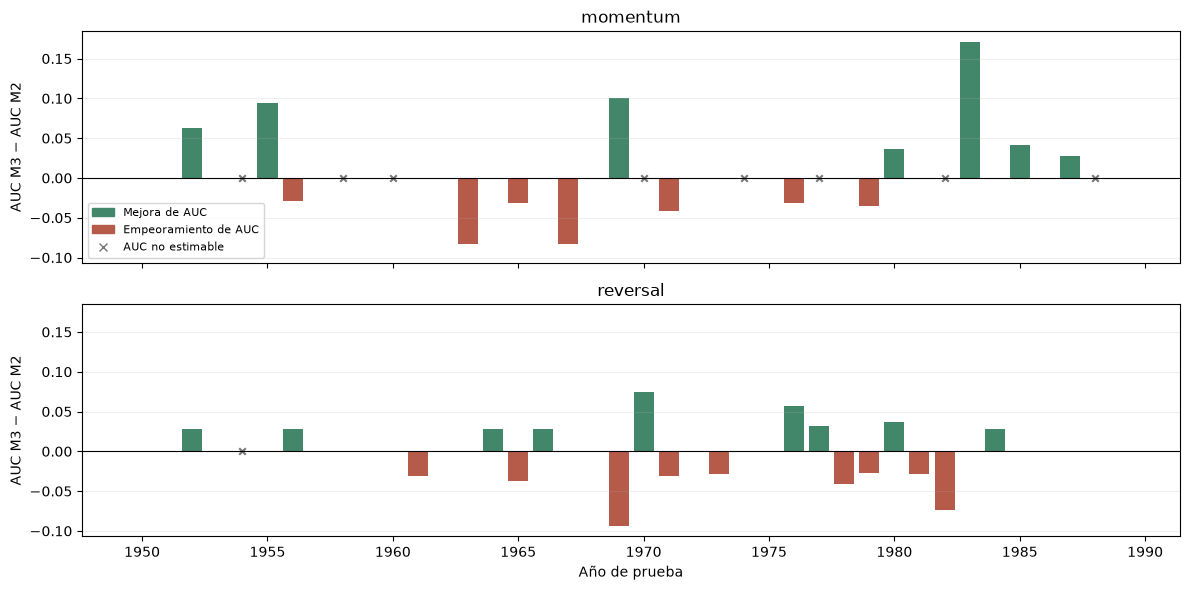

In [11]:
columnas_interaccion = ['reference_model', 'strategy', 'examples', 'auc_reference', 'auc_m3',
    'auc_improvement', 'log_loss_reference', 'log_loss_m3', 'log_loss_improvement', 'comparison_status']
display(comparacion_interaccion.loc[comparacion_interaccion.aggregation.eq('pooled'), columnas_interaccion])
display(pd.DataFrame(informe_interaccion['stability']))
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, sharey=True)
for ax, regla in zip(axes, ('momentum', 'reversal')):
    datos = comparacion_interaccion.loc[comparacion_interaccion.aggregation.eq('year') &
        comparacion_interaccion.reference_model.eq('M2') & comparacion_interaccion.strategy.eq(regla)]
    cambio = datos.auc_improvement.to_numpy(dtype=float)
    ax.bar(datos.test_year.to_numpy(dtype=int), cambio, color=np.where(cambio > 0, '#43876b', '#b65b49'))
    sin_auc = datos.loc[datos.auc_improvement.isna(), 'test_year'].to_numpy(dtype=int)
    ax.scatter(sin_auc, np.zeros(len(sin_auc)), marker='x', color='#777777', s=22)
    ax.axhline(0, color='black', linewidth=.8)
    ax.set(title=regla, ylabel='AUC M3 − AUC M2')
    ax.grid(axis='y', alpha=.2)
axes[0].legend(handles=[Patch(color='#43876b', label='Mejora de AUC'),
    Patch(color='#b65b49', label='Empeoramiento de AUC'),
    Line2D([0], [0], marker='x', color='#777777', linestyle='None', label='AUC no estimable')], fontsize=8)
axes[-1].set_xlabel('Año de prueba')
fig.tight_layout()
plt.show()

## 12. Guardar M3 y conservar las referencias

La interacción es un candidato previsto antes de ver M2, no se ha elegido probando distintas fórmulas tras sus resultados. Su tratamiento de la historia constante se ha fijado al comprobar cobertura y antes de ajustar M3. Las diez características originales y los cálculos de M0/M1/M2 se conservan.

La ejecución de esta sección lee las referencias publicadas y ajusta únicamente M3. Guarda cuatro tablas con sus JSON y registra una configuración adicional por regla en el historial compartido. Republicar M0/M1 o M2 retira estas salidas para evitar mezclar resultados de intentos distintos. Si falla el guardado, repite la celda completa.

Incluso si mejora, M3 no queda aceptado por estos resultados solamente: siguen pendientes sus contrastes específicos y la simulación económica. No se retocarán la interacción, sus ventanas o el criterio de estabilidad según la comparación obtenida. Antes del commit, limpia las salidas y guarda.

In [12]:
guardados_interaccion = []
for nombre, tabla in tablas_interaccion.items():
    salida = save_result(ROOT, nombre, tabla, informe_interaccion)
    guardados_interaccion.append({'Tabla': nombre + '.parquet', 'Filas': salida['rows']})
display(pd.DataFrame(guardados_interaccion))
print('Historial:', informe_interaccion['trial_log'])
print('Validación de M3 pendiente:', informe_interaccion['skill_gate_status'])

,Tabla,Filas
0,walk_forward_interaction_predictions.parquet,810
1,walk_forward_interaction_metrics.parquet,82
2,walk_forward_interaction_coefficients.parquet,560
3,walk_forward_interaction_comparison.parquet,164


Historial: outputs/experiments/walk_forward_trials.jsonl
Validación de M3 pendiente: pending_matched_cpcv_interaction_shadows_and_economic_evaluation


## 13. Retirar una variable cada vez: qué aporta dentro de M2

M2 reúne volatilidad, retorno de 24 meses y drawdown junto a las dos características de las señales. Ahora quitamos una de esas tres variables de régimen cada vez y **volvemos a entrenar** la logística con las cuatro columnas restantes. Conservamos años, etiquetas, ejemplos, purga y parámetros.

Es una comparación condicionada al resto de entradas. Una variable puede parecer prescindible porque otra recoge información similar. Su resultado tampoco demuestra causalidad ni una importancia válida para cualquier modelo. Este procedimiento se suele llamar *ablación* o retirada individual. Se diferencia de Clustered MDA: allí se desordena un grupo y se utiliza el modelo ya ajustado, aquí se elimina una columna y se ajusta otra vez.

Las tres variantes estaban previstas en el protocolo. No añadimos retiradas de combinaciones, otras ventanas o la interacción de M3. Se calcula un modelo por año, regla y retirada: 240 ajustes adicionales. M2 se lee como referencia, esta sección no lo reentrena ni cambia sus tablas.

In [13]:
from tfm.walk_forward_ablation import REMOVAL_MODELS, run_walk_forward_ablation

nombres_retiradas = {'z_price_volatility_12m': 'Volatilidad',
    'z_market_return_24m': 'Retorno de 24 meses', 'z_drawdown_12m': 'Drawdown'}
display(pd.DataFrame([{'Variable retirada': nombres_retiradas[c], 'Modelo': m}
                      for c, m in REMOVAL_MODELS.items()]))

def progreso_retiradas(completadas, total):
    if completadas == 1 or completadas % 10 == 0:
        print(f'Bloques de variante y año evaluados: {completadas}/{total}', flush=True)

tablas_retiradas, informe_retiradas = run_walk_forward_ablation(ROOT, progress=progreso_retiradas)
comparacion_retiradas = tablas_retiradas['walk_forward_ablation_comparison']
print('Estado del recorrido:', informe_retiradas['experiment_status'])

,Variable retirada,Modelo
0,Volatilidad,M2_without_volatility
1,Retorno de 24 meses,M2_without_market_state
2,Drawdown,M2_without_drawdown


Bloques de variante y año evaluados: 1/120
Bloques de variante y año evaluados: 10/120
Bloques de variante y año evaluados: 20/120
Bloques de variante y año evaluados: 30/120
Bloques de variante y año evaluados: 40/120
Bloques de variante y año evaluados: 50/120
Bloques de variante y año evaluados: 60/120
Bloques de variante y año evaluados: 70/120
Bloques de variante y año evaluados: 80/120
Bloques de variante y año evaluados: 90/120
Bloques de variante y año evaluados: 100/120
Bloques de variante y año evaluados: 110/120
Bloques de variante y año evaluados: 120/120
Estado del recorrido: completed


## 14. Leer la contribución de conservar la variable

Usamos una orientación distinta a la de «modelo nuevo menos referencia», para describir la aportación de la variable retirada:

- **Contribución de AUC = AUC de M2 completo − AUC sin la variable.**
- **Contribución de log-loss = log-loss sin la variable − log-loss de M2 completo.**

En ambos casos una cifra positiva favorece conservarla. Por ejemplo, si M2 tiene AUC 0,60 y al quitar la variable baja a 0,58, la contribución es +0,02. Si al quitarla sube a 0,62, es −0,02. Un empate en AUC puede acompañarse de probabilidades y log-loss diferentes.

Cada retirada usa los mismos meses. Los años sin AUC estimable siguen presentes. Los recuentos muestran contribuciones positivas, negativas, empates y años no estimables, una mayoría descriptiva tampoco acredita aceptación del régimen.
El AUC reunido también compara ejemplos de años distintos y no es una media de las AUC anuales. Por eso la contribución global puede ser negativa aunque haya más años con contribución positiva que negativa.


,strategy,Variable,examples,auc_m2,auc_without,auc_contribution,log_loss_m2,log_loss_without,log_loss_contribution,comparison_status
80,momentum,Volatilidad,331,0.594764,0.594129,0.000636,0.673069,0.670375,-0.002694,available
81,reversal,Volatilidad,479,0.635839,0.633973,0.001866,0.644421,0.643837,-0.000584,available
162,momentum,Retorno de 24 meses,331,0.594764,0.585677,0.009088,0.673069,0.676062,0.002993,available
163,reversal,Retorno de 24 meses,479,0.635839,0.622924,0.012916,0.644421,0.646537,0.002116,available
244,momentum,Drawdown,331,0.594764,0.600000,-0.005236,0.673069,0.668996,-0.004073,available
245,reversal,Drawdown,479,0.635839,0.640860,-0.005021,0.644421,0.643701,-0.000720,available


,strategy,removed_feature,expected_years,available_years,positive_contribution_years,negative_contribution_years,tied_years,unavailable_years,majority_required,positive_in_majority
0,momentum,z_price_volatility_12m,40,32,9,9,14,8,21,False
1,reversal,z_price_volatility_12m,40,39,8,4,27,1,21,False
2,momentum,z_market_return_24m,40,32,12,5,15,8,21,False
3,reversal,z_market_return_24m,40,39,17,6,16,1,21,False
4,momentum,z_drawdown_12m,40,32,11,4,17,8,21,False
5,reversal,z_drawdown_12m,40,39,10,8,21,1,21,False


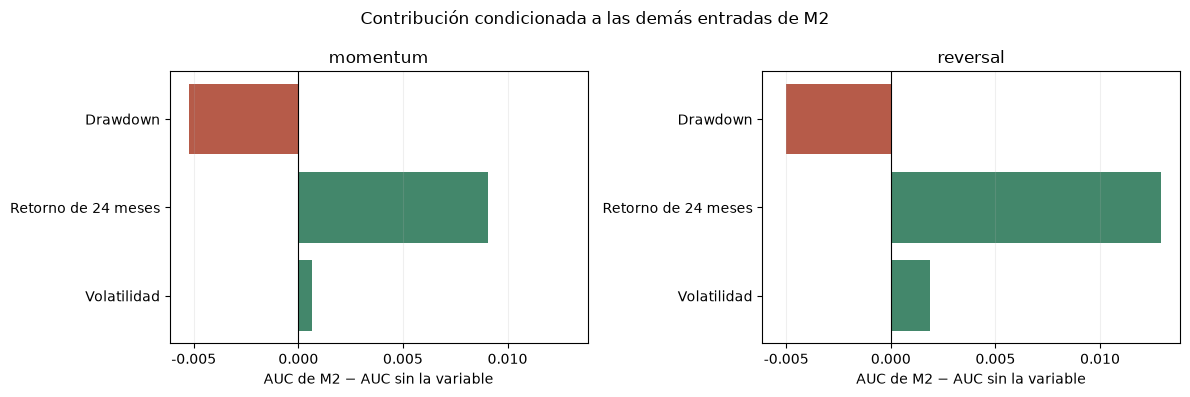

In [14]:
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

principal_retiradas = comparacion_retiradas.loc[comparacion_retiradas.aggregation.eq('pooled')].copy()
principal_retiradas['Variable'] = principal_retiradas.removed_feature.map(nombres_retiradas)
display(principal_retiradas[['strategy', 'Variable', 'examples', 'auc_m2', 'auc_without',
    'auc_contribution', 'log_loss_m2', 'log_loss_without', 'log_loss_contribution', 'comparison_status']])
display(pd.DataFrame(informe_retiradas['contributions']))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, regla in zip(axes, ('momentum', 'reversal')):
    datos = principal_retiradas.loc[principal_retiradas.strategy.eq(regla)]
    contribucion = datos.auc_contribution.to_numpy(dtype=float)
    ax.barh(datos.Variable, contribucion, color=np.where(contribucion > 0, '#43876b', '#b65b49'))
    ax.axvline(0, color='black', linewidth=.8)
    ax.set(title=regla, xlabel='AUC de M2 − AUC sin la variable')
    ax.grid(axis='x', alpha=.2)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.3f'))
fig.suptitle('Contribución condicionada a las demás entradas de M2')
fig.tight_layout()
plt.show()

## 15. Un diagnóstico, sin elegir automáticamente las variables

El análisis permite describir qué cambia al retirar cada columna. No convierte la mejor retirada observada en un modelo validado de forma independiente sobre estos mismos años. Si más adelante elegimos un subconjunto o una configuración por sus resultados, esa elección deberá realizarse dentro del entrenamiento y evaluarse por separado.

Se registran las tres variantes, incluidos resultados desfavorables. Los mismos meses aparecen una vez por variante: esas repeticiones no aumentan el número de observaciones independientes. El historial registra cada retirada antes de ajustarla, si falla una, se detiene el recorrido y no se publica una familia parcial. No se modifican M0/M1/M2/M3.

La siguiente celda guarda cuatro tablas `walk_forward_ablation_*`, con la columna retirada y el modelo identificados en cada fila. Republicar M0/M1 o M2 retira estas salidas, M3 no es una entrada y republicarlo las conserva. Si falla el guardado, repite la celda completa. La robustez CPCV equivalente se calcula a continuación. Siguen pendientes las sombras específicas, interpretación y evaluación económica.

In [15]:
guardados_retiradas = []
for nombre, tabla in tablas_retiradas.items():
    salida = save_result(ROOT, nombre, tabla, informe_retiradas)
    guardados_retiradas.append({'Tabla': nombre + '.parquet', 'Filas': salida['rows']})
display(pd.DataFrame(guardados_retiradas))
print('Historial:', informe_retiradas['trial_log'])
print('Alcance:', informe_retiradas['skill_gate_status'])

,Tabla,Filas
0,walk_forward_ablation_predictions.parquet,2430
1,walk_forward_ablation_metrics.parquet,246
2,walk_forward_ablation_coefficients.parquet,1200
3,walk_forward_ablation_comparison.parquet,246


Historial: outputs/experiments/walk_forward_trials.jsonl
Alcance: diagnostic_only_no_automatic_selection_or_regime_acceptance


## 16. Repetir las comparaciones con CPCV

Hasta aquí hemos probado años futuros usando solo entrenamiento anterior. Ahora comprobamos los mismos seis candidatos con las quince particiones del notebook 10: M1, M2, M3 y las tres retiradas de M2. Usamos las mismas columnas y parámetros, no elegimos los candidatos que hayan salido mejor en walk-forward.

Cada partición reserva dos de los seis bloques y entrena con los otros cuatro, respetando purga de un mes y embargo de seis. Puede aprender de bloques posteriores a su prueba, por eso es una comprobación de robustez sobre el desarrollo, no una reproducción de decisiones en tiempo real ni evidencia independiente.

La interacción de M3 y las otras transformaciones se calculan con el pasado de cada fecha antes de distribuir los bloques. No se normalizan los meses iniciales utilizando estadísticas de los bloques futuros de entrenamiento. La muestra común y sus limitaciones se mantienen.

**Entradas de esta sección:** 07/08 y las dos tablas del 10, preparadas a partir de 01/02. No necesita resultados de 11–13 ni de las secciones walk-forward. Si faltan las particiones, ejecuta el 10 antes de continuar. Los cálculos y la interpretación están en [el protocolo CPCV](../docs/cpcv_regimen.md).

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import display
from tfm.data import project_root, save_result
from tfm.cpcv_regime import CANDIDATE_COLUMNS, run_cpcv_regime

ROOT = project_root()
display(pd.DataFrame([{'Modelo': m, 'Predictores': ', '.join(c)} for m, c in CANDIDATE_COLUMNS.items()]))
def progreso_cpcv(completadas, total):
    if completadas == 1 or completadas % 15 == 0:
        print(f'Combinaciones de candidato y partición: {completadas}/{total}', flush=True)

tablas_cpcv, informe_cpcv = run_cpcv_regime(ROOT, progress=progreso_cpcv)
metricas_cpcv = tablas_cpcv['cpcv_regime_metrics']
comparacion_cpcv = tablas_cpcv['cpcv_regime_comparison']
print('Estado del recorrido:', informe_cpcv['experiment_status'])
display(pd.DataFrame(informe_cpcv['diagnostics']))

,Modelo,Predictores
0,M1,"z_price_return_1m, z_momentum_12_1"
1,M2,"z_price_return_1m, z_momentum_12_1, z_price_vo..."
2,M3,"z_price_return_1m, z_momentum_12_1, z_price_vo..."
3,M2_without_volatility,"z_price_return_1m, z_momentum_12_1, z_market_r..."
4,M2_without_market_state,"z_price_return_1m, z_momentum_12_1, z_price_vo..."
5,M2_without_drawdown,"z_price_return_1m, z_momentum_12_1, z_price_vo..."


Combinaciones de candidato y partición: 1/90
Combinaciones de candidato y partición: 15/90
Combinaciones de candidato y partición: 30/90
Combinaciones de candidato y partición: 45/90
Combinaciones de candidato y partición: 60/90
Combinaciones de candidato y partición: 75/90
Combinaciones de candidato y partición: 90/90
Estado del recorrido: completed


,candidate_model,split_id,strategy,train_examples,validation_examples,train_positive,iterations,status
0,M1,1,momentum,342,98,196,8,completed
1,M1,1,reversal,497,207,185,8,completed
2,M1,2,momentum,303,130,168,10,completed
3,M1,2,reversal,490,207,189,7,completed
4,M1,3,momentum,304,128,178,9,completed
...,...,...,...,...,...,...,...,...
175,M2_without_drawdown,13,reversal,452,251,166,12,completed
176,M2_without_drawdown,14,momentum,250,185,150,12,completed
177,M2_without_drawdown,14,reversal,450,252,170,13,completed
178,M2_without_drawdown,15,momentum,283,158,174,11,completed


## 17. Cinco predicciones de cada ejemplo, sin multiplicar la muestra

Cada mes utilizable aparece en cinco particiones de prueba. Conservamos esas cinco probabilidades y, para el resumen de cada candidato, calculamos su media por regla y mes, igual que en el notebook 11. M0 se calcula con la frecuencia positiva del entrenamiento de cada partición y recibe el mismo tratamiento. Su referencia es idéntica para los seis candidatos y se guarda una vez en las métricas. La frecuencia puede variar entre particiones y su media mensual entre fechas, por eso su AUC reunida no tiene por qué ser 0,5.

Las cinco apariciones no son cinco observaciones independientes. Su media tampoco es una trayectoria CPCV de rentabilidades ni una cartera. Si falta una de las cinco probabilidades, su media queda ausente y no se calcula una métrica ignorando ese mes. Conservamos las particiones sin ejemplos o con una clase, indicando cuándo AUC no puede calcularse.

Mostramos dos resúmenes, fijados antes del cálculo: `monthly_mean` usa todo el desarrollo utilizable, `common_period` restringe esas mismas medias a 1950–1989, los meses de prueba del walk-forward. Este segundo resumen no reentrena ni cambia los bloques. Alinear meses no iguala la información de entrenamiento ni convierte ambos procedimientos en pruebas independientes. Por eso no se comparan sus AUC como si solo cambiara el modelo.

,aggregation,strategy,model,examples,log_loss,auc,status
60,monthly_mean,momentum,M1,442,0.663221,0.593238,completed
61,monthly_mean,momentum,M0,442,0.680904,0.433950,completed
62,monthly_mean,reversal,M1,710,0.649677,0.616303,completed
63,monthly_mean,reversal,M0,710,0.660392,0.473115,completed
64,common_period,momentum,M1,331,0.672795,0.578422,completed
65,common_period,momentum,M0,331,0.685605,0.424607,completed
66,common_period,reversal,M1,479,0.645111,0.632218,completed
67,common_period,reversal,M0,479,0.660095,0.485479,completed
98,monthly_mean,momentum,M2,442,0.665993,0.589053,completed
99,monthly_mean,reversal,M2,710,0.653758,0.606935,completed


,aggregation,reference_model,candidate_model,removed_feature,strategy,examples,auc_reference,auc_candidate,auc_improvement,log_loss_improvement,comparison_status
0,common_period,M1,M2,None,momentum,331,0.578422,0.573897,-0.004525,-0.003744,available
1,common_period,M1,M2,None,reversal,479,0.632218,0.638938,0.006719,0.002198,available
2,monthly_mean,M1,M2,None,momentum,442,0.593238,0.589053,-0.004184,-0.002772,available
3,monthly_mean,M1,M2,None,reversal,710,0.616303,0.606935,-0.009368,-0.004082,available
34,common_period,M1,M3,None,momentum,331,0.578422,0.584144,0.005722,-0.001458,available
35,common_period,M1,M3,None,reversal,479,0.632218,0.638695,0.006477,0.003074,available
36,monthly_mean,M1,M3,None,momentum,442,0.593238,0.599091,0.005854,-0.000712,available
37,monthly_mean,M1,M3,None,reversal,710,0.616303,0.608541,-0.007763,-0.002957,available
68,common_period,M2,M3,None,momentum,331,0.573897,0.584144,0.010247,0.002286,available
69,common_period,M2,M3,None,reversal,479,0.638938,0.638695,-0.000243,0.000876,available


,reference_model,candidate_model,removed_feature,strategy,expected_partitions,available_partitions,improved_partitions,worsened_partitions,tied_partitions,unavailable_partitions,majority_required,meets_majority
0,M1,M2,NaN,momentum,15,15,7,8,0,0,8,False
1,M1,M2,NaN,reversal,15,15,9,6,0,0,8,True
2,M1,M3,NaN,momentum,15,15,10,5,0,0,8,True
3,M1,M3,NaN,reversal,15,15,8,7,0,0,8,True
4,M2,M3,NaN,momentum,15,15,10,5,0,0,8,True
5,M2,M3,NaN,reversal,15,15,8,7,0,0,8,True
6,M2_without_volatility,M2,z_price_volatility_12m,momentum,15,15,10,5,0,0,8,True
7,M2_without_volatility,M2,z_price_volatility_12m,reversal,15,15,7,7,1,0,8,False
8,M2_without_market_state,M2,z_market_return_24m,momentum,15,15,12,3,0,0,8,True
9,M2_without_market_state,M2,z_market_return_24m,reversal,15,15,11,4,0,0,8,True


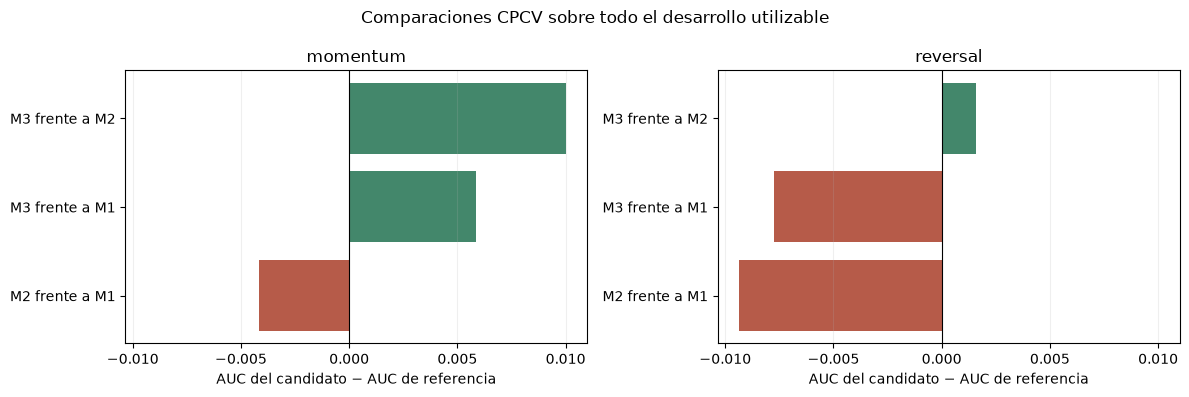

In [17]:
from matplotlib.ticker import MaxNLocator

display(metricas_cpcv.loc[metricas_cpcv.aggregation.isin(['monthly_mean', 'common_period']),
    ['aggregation', 'strategy', 'model', 'examples', 'log_loss', 'auc', 'status']])
display(comparacion_cpcv.loc[comparacion_cpcv.aggregation.isin(['monthly_mean', 'common_period']),
    ['aggregation', 'reference_model', 'candidate_model', 'removed_feature', 'strategy', 'examples',
     'auc_reference', 'auc_candidate', 'auc_improvement', 'log_loss_improvement', 'comparison_status']])
display(pd.DataFrame(informe_cpcv['stability']))

principal_cpcv = comparacion_cpcv.loc[comparacion_cpcv.aggregation.eq('monthly_mean') &
    comparacion_cpcv.removed_feature.isna()].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
for ax, regla in zip(axes, ('momentum', 'reversal')):
    datos = principal_cpcv.loc[principal_cpcv.strategy.eq(regla)]
    etiquetas = datos.candidate_model + ' frente a ' + datos.reference_model
    cambio = datos.auc_improvement.to_numpy(dtype=float)
    ax.barh(etiquetas, cambio, color=np.where(cambio > 0, '#43876b', '#b65b49'))
    ax.axvline(0, color='black', linewidth=.8)
    ax.set(title=regla, xlabel='AUC del candidato − AUC de referencia')
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.grid(axis='x', alpha=.2)
fig.suptitle('Comparaciones CPCV sobre todo el desarrollo utilizable')
fig.tight_layout()
plt.show()

## 18. Qué añade esta comprobación y qué sigue pendiente

La tabla separa la aportación del bloque (M2 frente a M1), la interacción (M3 frente a M2 y M1) y la contribución de mantener cada variable (M2 frente al modelo que la retira). Una diferencia positiva favorece siempre al candidato indicado. En las retiradas ese candidato es M2 completo, por lo que una cifra positiva favorece conservar la variable.

La estabilidad se describe sobre las quince particiones: mayoría estricta significa al menos ocho con mejora. Las particiones comparten meses y episodios, así que no son quince experimentos independientes. El resumen común de 1950–1989 ayuda a interpretar diferencias de muestra, pero no sustituye el resultado CPCV completo ni la evaluación cronológica.

Se mantienen las listas fijadas y no se cambia una decisión por escoger ahora la validación más favorable. CPCV utiliza las mismas configuraciones ya registradas: su historial identifica la nueva validación, sin contabilizar otras seis listas o hiperparámetros nuevos. No se ha calculado DSR/PBO a partir del número de particiones. Tampoco una mejora conjunta de estas métricas acredita por sí sola rentabilidad o aceptación del régimen: quedan las sombras específicas, la estabilidad exigida en ambos esquemas y la evaluación económica.

Esta sección guarda cinco tablas `cpcv_regime_*` e historial separado, sin modificar los resultados originales del 11–13 o del walk-forward. Recalcular características, etiquetas o las particiones del 10 retira estas salidas. Republicar los modelos anteriores las conserva, porque no son sus entradas. Si falla el guardado, repite la celda completa. El periodo desde 1990 sigue reservado. Antes del commit, limpia las salidas y guarda.

In [18]:
guardados_cpcv = []
for nombre, tabla in tablas_cpcv.items():
    salida = save_result(ROOT, nombre, tabla, informe_cpcv)
    guardados_cpcv.append({'Tabla': nombre + '.parquet', 'Filas': salida['rows']})
display(pd.DataFrame(guardados_cpcv))
print('Historial:', informe_cpcv['trial_log'])
print('Validación pendiente:', informe_cpcv['skill_gate_status'])

,Tabla,Filas
0,cpcv_regime_predictions.parquet,34560
1,cpcv_regime_monthly.parquet,6912
2,cpcv_regime_metrics.parquet,238
3,cpcv_regime_coefficients.parquet,930
4,cpcv_regime_comparison.parquet,204


Historial: outputs/experiments/cpcv_regime_trials.jsonl
Validación pendiente: pending_candidate_shadows_and_economic_evaluation_no_regime_acceptance


## 19. De probabilidades a decisiones de inversión

Ahora usamos las predicciones **walk-forward**, una por operación activa, para simular cuentas continuas. No usamos las medias CPCV ni capitalizamos los retornos aislados del etiquetado. Esta sección puede ejecutarse en un kernel nuevo con 01/02/07/08 y los resultados M0/M1, M2 y M3 ya preparados, no requiere repetir ajustes, sombras, CPCV o las retiradas individuales.

Fijamos el criterio antes de calcular estas curvas: aceptar la señal original si su probabilidad es **mayor que 0,5**, con 0,5 o menos, mantener efectivo. Por ejemplo, una reversión corta con probabilidad 0,62 sigue siendo corta, con 0,43 se rechaza. El modelo no cambia la dirección ni el tamaño de una señal aceptada. Una señal original cero sigue siendo efectivo y no necesita predicción. Si falta una probabilidad para una señal activa, el cálculo se detiene.

El 50 % es una convención de clasificación, no un umbral óptimo demostrado: acertar muchas operaciones pequeñas no garantiza compensar unas pocas pérdidas grandes. Tampoco asegura que las probabilidades estén calibradas. No buscaremos ahora otro umbral que mejore estas curvas. El diseño completo está en [el protocolo económico](../docs/evaluacion_economica.md).


In [19]:
from tfm.data import project_root, save_result
from tfm.economics import run_economics
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = project_root()
tablas_economicas, informe_economico = run_economics(ROOT)
decisiones_economicas = tablas_economicas['walk_forward_economic_decisions']
cuentas_economicas = tablas_economicas['walk_forward_economic_simulations']
metricas_economicas = tablas_economicas['walk_forward_economic_metrics']
comparacion_economica = tablas_economicas['walk_forward_economic_comparison']
display(pd.DataFrame([informe_economico['parameters']]))
display(pd.DataFrame([informe_economico['decision_policy']]))
display(metricas_economicas.loc[metricas_economicas.active_signals.notna(),
    ['label', 'active_signals', 'accepted_signals', 'rejected_signals']])


,initial_capital,transaction_cost_rate,annual_borrow_rate,include_dividends
0,100.0,0.001,0.01,True


,threshold,operator,tie,no_signal,missing_active_prediction,sizing,threshold_selection
0,0.5,>,cash,cash_without_prediction,stop,original_signal_or_cash,fixed_without_search


,label,active_signals,accepted_signals,rejected_signals
6,Momentum · M0,331,331,0
7,Momentum · M1,331,284,47
8,Momentum · M2,331,270,61
9,Momentum · M3,331,274,57
12,Reversión · M0,479,0,479
13,Reversión · M1,479,43,436
14,Reversión · M2,479,47,432
15,Reversión · M3,479,46,433


## 20. Las cuentas empiezan y terminan en las mismas fechas

Todas parten de efectivo con capital 100 en enero de 1950 y terminan con liquidación en diciembre de 1989. Conservamos los 480 meses, incluidos los rechazados y los meses sin señal. El reentrenamiento anual no reinicia el capital ni cierra automáticamente una posición en diciembre.

Reutilizamos el mismo motor contable: dividendos aproximados, remuneración RF del efectivo, negociación sobre el nominal realmente cambiado y préstamo de los cortos. Rechazar una señal puede requerir cerrar una posición anterior y pagar su coste. Aceptar dos señales consecutivas no fuerza venta y recompra mensual. Las etiquetas evaluaban operaciones aisladas, estas curvas evalúan posiciones continuas y por eso sus retornos no se pueden intercambiar.

Se recalculan las referencias con el mismo inicio y final: comprar y mantener, efectivo, reglas sin filtrar, veto bajista y ajuste por volatilidad. Este último mantiene ventana de 12 meses, objetivo anual del 12 % y exposición máxima uno. Ninguna comparación reutiliza una curva que ya hubiera acumulado capital desde 1927.

La tabla conserva las dieciséis cuentas, incluidos los filtros M0. El gráfico muestra M1–M3 y las referencias sin filtro, por volatilidad y en efectivo, las demás cuentas siguen disponibles en las tablas. Cada panel usa su propia escala vertical para apreciar los cambios dentro de su regla, no para comparar alturas entre paneles. Las curvas usan precios medios mensuales de Shiller: son aproximaciones históricas, no operaciones ejecutables a precios de cierre.


,label,capital_final,annualized_return,annualized_volatility,sharpe,max_drawdown,annualized_turnover,transaction_cost_total,borrow_cost_total
0,Comprar y mantener,10652.287426,12.379235,11.796636,0.614253,-39.156829,0.050660,10.762850,0.000000
1,Efectivo,761.011522,5.204612,0.905039,NaN,0.000000,0.000000,0.000000,0.000000
2,Momentum,4665.135290,10.083342,9.277165,0.532213,-26.037362,0.850260,36.846847,0.000000
3,Reversión,9.738130,-5.656521,12.147662,-0.841690,-90.755474,10.248453,14.889546,9.073072
4,Momentum · veto bajista,4299.250220,9.858792,8.867085,0.529430,-26.037362,1.000186,38.039942,0.000000
5,Momentum · ajuste por volatilidad,4321.312403,9.872850,8.843705,0.531349,-21.789446,0.891956,35.968089,0.000000
6,Momentum · M0,4665.135290,10.083342,9.277165,0.532213,-26.037362,0.850260,36.846847,0.000000
7,Momentum · M1,6178.890627,10.859461,7.975752,0.689690,-14.018484,1.899051,92.497920,0.000000
8,Momentum · M2,6900.550794,11.166029,7.837115,0.734549,-14.018484,2.498751,139.828940,0.000000
9,Momentum · M3,7245.997717,11.301868,7.810717,0.753831,-14.018484,2.448776,136.054569,0.000000


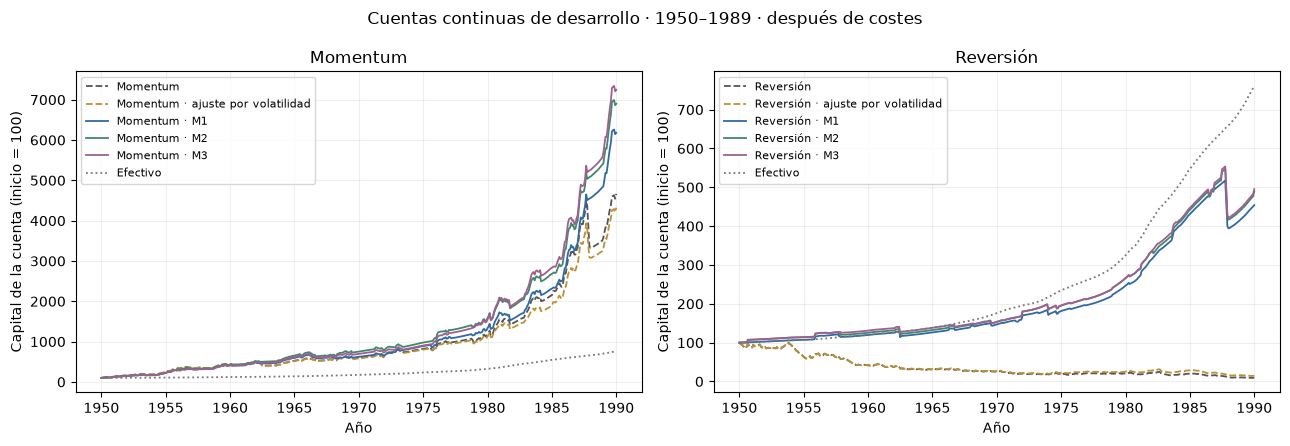

In [20]:
resumen_economico = metricas_economicas[['label', 'capital_final', 'annualized_return',
    'annualized_volatility', 'sharpe', 'max_drawdown', 'annualized_turnover',
    'transaction_cost_total', 'borrow_cost_total']].copy()
# Retorno, volatilidad y drawdown se muestran como porcentajes, los costes, en unidades de capital.
for columna in ('annualized_return', 'annualized_volatility', 'max_drawdown'):
    resumen_economico[columna] *= 100
display(resumen_economico)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)
colores = {'': '#555555', '_volatility': '#bb9135', '_m1': '#3069a3',
           '_m2': '#43876b', '_m3': '#a15f90'}
for ax, regla, titulo in zip(axes, ('momentum', 'reversal'), ('Momentum', 'Reversión')):
    curvas = [(regla + sufijo, color) for sufijo, color in colores.items()] + [('cash', '#777777')]
    for cuenta, color in curvas:
        datos = cuentas_economicas.loc[cuentas_economicas.strategy.eq(cuenta)]
        etiqueta = informe_economico['accounts'][cuenta]
        fechas = pd.PeriodIndex(datos.period, freq='M').to_timestamp(how='end')
        # El punto inicial permite ver el coste de apertura sin perderlo en el primer mes.
        inicio = pd.Timestamp(informe_economico['test_interval'][0] + '-01')
        ax.plot([inicio, *fechas], [informe_economico['parameters']['initial_capital'], *datos.capital_end],
                label=etiqueta, color=color, linewidth=1.3,
                linestyle=':' if cuenta == 'cash' else '--' if cuenta in (regla, regla + '_volatility') else '-')
    ax.set(title=titulo, xlabel='Año', ylabel='Capital de la cuenta (inicio = 100)')
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.suptitle('Cuentas continuas de desarrollo · 1950–1989 · después de costes')
fig.tight_layout()
plt.show()


## 21. Qué compara el Sharpe y qué no demuestra

El Sharpe resume el exceso mensual de la cuenta sobre RF dividido por su variabilidad, anualizado con raíz de doce. Mayor es favorable, pero no demuestra por sí solo significación ni una mejora estable. Una cuenta siempre en efectivo tiene exceso cero y Sharpe no estimable, no lo reemplazamos por infinito ni lo tratamos como una victoria.

Las diferencias siguientes son Sharpe del candidato menos Sharpe de su referencia. Cada filtro se compara con su regla sin filtrar, el veto y la escala por volatilidad. Además contrastamos M2 y M3 con M1, y M3 con M2. Conservamos también diferencias desfavorables y comparaciones no estimables. No cambiamos el umbral, la muestra o los modelos al ver la tabla.

M2 y M3 no alcanzaron la mayoría anual de mejoras predictivas exigida. Una curva o un Sharpe favorable no elimina ese incumplimiento y estas tablas no aceptan el régimen. Las sombras específicas que correspondan, los demás candidatos y los controles de sobreajuste siguen siendo trabajos separados. No calculamos DSR/PBO a partir de probabilidades ni generamos SHAP con estas curvas. El periodo desde 1990 continúa reservado.


In [21]:
display(comparacion_economica[['rule', 'model', 'reference', 'sharpe_candidate',
    'sharpe_reference', 'sharpe_improvement', 'comparison_status']])


,rule,model,reference,sharpe_candidate,sharpe_reference,sharpe_improvement,comparison_status
0,momentum,M0,unfiltered,0.532213,0.532213,0.000000,available
1,momentum,M0,bear,0.532213,0.529430,0.002783,available
2,momentum,M0,volatility,0.532213,0.531349,0.000864,available
3,momentum,M1,unfiltered,0.689690,0.532213,0.157476,available
4,momentum,M1,bear,0.689690,0.529430,0.160260,available
5,momentum,M1,volatility,0.689690,0.531349,0.158340,available
6,momentum,M2,unfiltered,0.734549,0.532213,0.202336,available
7,momentum,M2,bear,0.734549,0.529430,0.205119,available
8,momentum,M2,volatility,0.734549,0.531349,0.203200,available
9,momentum,M3,unfiltered,0.753831,0.532213,0.221618,available


## 22. Guardar el diagnóstico económico

Guardamos las decisiones, las cuentas mensuales, sus métricas y las comparaciones. El historial identifica el umbral fijo y los resultados predictivos utilizados, no se ajustan modelos nuevos. Repetir el cálculo con las mismas entradas no crea otra configuración.

Las cuatro tablas económicas se retiran si regeneramos sus datos o republicamos M0/M1, M2 o M3. Publicar CPCV, sombras o las retiradas individuales las conserva porque no son sus entradas. Esta sección no modifica las cuentas ni los experimentos anteriores. Si falla el guardado, repite la celda completa. Antes del commit, limpia las salidas y guarda el notebook.


In [22]:
guardados_economicos = []
for nombre, tabla in tablas_economicas.items():
    salida = save_result(ROOT, nombre, tabla, informe_economico)
    guardados_economicos.append({'Tabla': nombre + '.parquet', 'Filas': salida['rows']})
display(pd.DataFrame(guardados_economicos))
print('Historial:', informe_economico['trial_log'])
print('Alcance:', informe_economico['regime_acceptance'])


,Tabla,Filas
0,walk_forward_economic_decisions.parquet,3840
1,walk_forward_economic_simulations.parquet,7680
2,walk_forward_economic_metrics.parquet,16
3,walk_forward_economic_comparison.parquet,30


Historial: outputs/experiments/walk_forward_economics_trials.jsonl
Alcance: not_assessed_economic_comparison_only


## 23. Segundo candidato: un random forest pequeño

La logística transforma una suma de variables en una probabilidad. Un árbol plantea preguntas sucesivas: por ejemplo, si la volatilidad es alta y después si el retorno anterior es negativo. Un bosque combina muchos árboles y promedia sus probabilidades. Esto permite representar relaciones no lineales, pero también aprender casualidades del pasado si le damos demasiada libertad.

Fijamos antes del ajuste **200 árboles, profundidad máxima 3, mínimo 20 observaciones por hoja y semilla 42**. Cada árbol puede tener como máximo ocho hojas. Todos los candidatos usan estos parámetros, bootstrap del entrenamiento y todas sus columnas como opciones de división. No buscamos otros parámetros ni equilibramos clases artificialmente. Una hoja puede dar una probabilidad poco fiable, el promedio no garantiza calibración.

Comparamos **RF_M1**, con las dos variables de señal, **RF_M2**, que añade las tres variables de régimen, y **RF_M3**, que incorpora además el producto mercado bajista × volatilidad. RF_M2 ya puede aprender interacciones. RF_M3 comprueba si añadir ese producto explícito facilita la representación, no si aparecen interacciones por primera vez.

Conservamos las transformaciones y la muestra común para comparar familias sin cambiar también la preparación de datos. Un árbol no necesita z-score, pero la transformación común y la winsorización siguen formando parte del experimento fijado. No se usa el cribado para seleccionar columnas ni se toman importancias Gini como sustituto de Clustered MDA.

**Entradas:** 01/02/07/08 y resultados M0/M1/M2 logísticos. Esta sección puede ejecutarse en un kernel nuevo, no requiere M3 logístico, CPCV, sombras o cuentas económicas. No vuelve a ajustar la logística. El diseño y las limitaciones están en [el protocolo del bosque](../docs/random_forest.md).


In [23]:
from tfm.data import project_root, save_result
from tfm.forest import run_forest, FOREST_PARAMETERS, CANDIDATE_COLUMNS
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display

ROOT = project_root()
display(pd.DataFrame([FOREST_PARAMETERS]))
display(pd.DataFrame([{'Modelo': modelo, 'Columnas': ', '.join(columnas)}
    for modelo, columnas in CANDIDATE_COLUMNS.items()]))

def progreso_bosque(completados, total):
    if completados % 10 == 0 or completados == total:
        print(f'Combinaciones de candidato y año: {completados}/{total}')

tablas_bosque, informe_bosque = run_forest(ROOT, progress=progreso_bosque)
metricas_bosque = tablas_bosque['forest_walk_forward_metrics']
comparacion_bosque = tablas_bosque['forest_walk_forward_comparison']
display(metricas_bosque.loc[metricas_bosque.aggregation.eq('pooled'),
    ['strategy', 'model', 'examples', 'positive', 'negative', 'auc', 'log_loss', 'status']])


,n_estimators,criterion,max_depth,min_samples_split,min_samples_leaf,max_features,bootstrap,max_samples,class_weight,random_state,n_jobs,max_leaf_nodes,min_impurity_decrease,ccp_alpha
0,200,gini,3,2,20,1.0,True,None,None,42,1,None,0.0,0.0


,Modelo,Columnas
0,RF_M1,"z_price_return_1m, z_momentum_12_1"
1,RF_M2,"z_price_return_1m, z_momentum_12_1, z_price_vo..."
2,RF_M3,"z_price_return_1m, z_momentum_12_1, z_price_vo..."


Combinaciones de candidato y año: 10/120
Combinaciones de candidato y año: 20/120
Combinaciones de candidato y año: 30/120
Combinaciones de candidato y año: 40/120
Combinaciones de candidato y año: 50/120
Combinaciones de candidato y año: 60/120
Combinaciones de candidato y año: 70/120
Combinaciones de candidato y año: 80/120
Combinaciones de candidato y año: 90/120
Combinaciones de candidato y año: 100/120
Combinaciones de candidato y año: 110/120
Combinaciones de candidato y año: 120/120


,strategy,model,examples,positive,negative,auc,log_loss,status
80,momentum,M0,331,191,140,0.497251,0.684939,completed
81,reversal,M0,479,178,301,0.416244,0.661412,completed
162,momentum,RF_M1,331,191,140,0.600430,0.684830,completed
163,reversal,RF_M1,479,178,301,0.669165,0.622724,completed
244,momentum,RF_M2,331,191,140,0.598298,0.675990,completed
245,reversal,RF_M2,479,178,301,0.668063,0.626402,completed
326,momentum,RF_M3,331,191,140,0.598336,0.676924,completed
327,reversal,RF_M3,479,178,301,0.663733,0.628493,completed


## 24. Qué añade el bosque y qué aporta el régimen dentro del bosque

Repetimos los cuarenta años de prueba de 1950–1989, con entrenamiento expansivo hasta noviembre del año anterior y diciembre purgado. La semilla y los parámetros son iguales para las tres listas. Los resultados de cada año usan únicamente sus ejemplos reservados, las métricas reunidas usan una predicción por operación, sin medias CPCV ni promedios de AUC anuales.

Separamos dos preguntas. RF_M1 frente a L2_M1 y RF_M2 frente a L2_M2 comparan **familias de modelos con las mismas columnas**. RF_M2 frente a RF_M1, RF_M3 frente a RF_M1 y RF_M3 frente a RF_M2 miden la aportación de añadir entradas dentro del bosque. La logística mantiene sus resultados originales.

En las tablas y el gráfico, una diferencia positiva favorece al candidato: AUC del candidato menos referencia, o log-loss de referencia menos candidato. Un año vacío o con una sola clase sigue presente, si no puede calcularse AUC, no cuenta como mejora. Se necesitan al menos veintiún años favorables de los cuarenta previstos para la mayoría establecida, sin cambiar el denominador.

Una mejora frente a la logística no acepta automáticamente el régimen. Tampoco un buen resultado estadístico demuestra una mejora de inversión: CPCV equivalente, sombras específicas y cuentas económicas del bosque siguen pendientes. Las sombras del modelo logístico anterior no validan este nuevo candidato. No elegimos ahora el mejor bosque o eliminamos variables al mirar estos resultados.


,reference_model,candidate_model,strategy,auc_reference,auc_candidate,auc_improvement,log_loss_improvement,comparison_status
80,RF_M1,RF_M2,momentum,0.600430,0.598298,-0.002132,0.008840,available
81,RF_M1,RF_M2,reversal,0.669165,0.668063,-0.001101,-0.003678,available
162,RF_M1,RF_M3,momentum,0.600430,0.598336,-0.002094,0.007906,available
163,RF_M1,RF_M3,reversal,0.669165,0.663733,-0.005431,-0.005770,available
244,RF_M2,RF_M3,momentum,0.598298,0.598336,0.000037,-0.000934,available
245,RF_M2,RF_M3,reversal,0.668063,0.663733,-0.004330,-0.002091,available
326,L2_M1,RF_M1,momentum,0.595625,0.600430,0.004806,-0.015830,available
327,L2_M1,RF_M1,reversal,0.630296,0.669165,0.038869,0.022236,available
408,L2_M2,RF_M2,momentum,0.594764,0.598298,0.003534,-0.002922,available
409,L2_M2,RF_M2,reversal,0.635839,0.668063,0.032224,0.018019,available


,reference_model,candidate_model,strategy,expected_years,auc_available_years,auc_improved_years,auc_worsened_years,auc_tied_years,auc_unavailable_years,majority_required,meets_majority
0,RF_M1,RF_M2,momentum,40,32,10,17,5,8,21,False
1,RF_M1,RF_M2,reversal,40,39,17,14,8,1,21,False
2,RF_M1,RF_M3,momentum,40,32,11,16,5,8,21,False
3,RF_M1,RF_M3,reversal,40,39,18,14,7,1,21,False
4,RF_M2,RF_M3,momentum,40,32,5,5,22,8,21,False
5,RF_M2,RF_M3,reversal,40,39,4,8,27,1,21,False
6,L2_M1,RF_M1,momentum,40,32,17,10,5,8,21,False
7,L2_M1,RF_M1,reversal,40,39,15,17,7,1,21,False
8,L2_M2,RF_M2,momentum,40,32,19,11,2,8,21,False
9,L2_M2,RF_M2,reversal,40,39,13,18,8,1,21,False


,candidate,ajustes,profundidad_maxima,hojas_medias,estado
0,RF_M1,80,3,6.058125,completed
1,RF_M2,80,3,6.041813,completed
2,RF_M3,80,3,6.071937,completed


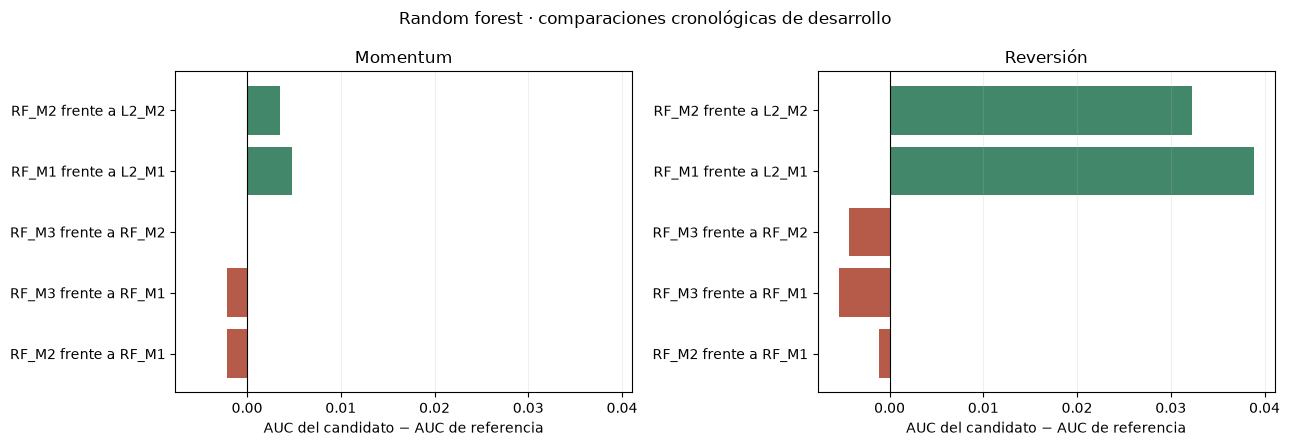

In [24]:
display(comparacion_bosque.loc[comparacion_bosque.aggregation.eq('pooled'),
    ['reference_model', 'candidate_model', 'strategy', 'auc_reference', 'auc_candidate',
     'auc_improvement', 'log_loss_improvement', 'comparison_status']])
display(pd.DataFrame(informe_bosque['stability']))
display(tablas_bosque['forest_walk_forward_diagnostics'].groupby('candidate', sort=False).agg(
    ajustes=('status', 'size'), profundidad_maxima=('max_observed_depth', 'max'),
    hojas_medias=('mean_leaves', 'mean'), estado=('status', lambda x: ', '.join(sorted(set(x))))).reset_index())

principal_bosque = comparacion_bosque.loc[comparacion_bosque.aggregation.eq('pooled')]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, regla, titulo in zip(axes, ('momentum', 'reversal'), ('Momentum', 'Reversión')):
    datos = principal_bosque.loc[principal_bosque.strategy.eq(regla)]
    etiquetas = datos.candidate_model + ' frente a ' + datos.reference_model
    cambios = datos.auc_improvement.to_numpy(dtype=float)
    ax.barh(etiquetas, cambios, color=['#43876b' if x > 0 else '#b65b49' for x in cambios])
    ax.axvline(0, color='black', linewidth=.8)
    ax.set(title=titulo, xlabel='AUC del candidato − AUC de referencia')
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.grid(axis='x', alpha=.2)
fig.suptitle('Random forest · comparaciones cronológicas de desarrollo')
fig.tight_layout()
plt.show()


## 25. Guardar el segundo candidato y conservar sus límites

Se guardan las predicciones, las métricas, el diagnóstico de los ajustes y las cinco comparaciones. Cada lista constituye una nueva configuración por regla, los 200 árboles y cuarenta años no son configuraciones independientes. El historial registra cada intento antes de ajustar y conserva resultados o fallos. Si una lista falla, el recorrido se detiene sin devolver una familia parcial para publicar.

Estas tablas dependen de las características, etiquetas y referencias M0/M1/M2 logísticas. Regenerar sus entradas o republicar esas referencias retira las tablas del bosque. Publicar M3 logístico, CPCV, sombras, retiradas o cuentas económicas las conserva porque no son entradas de este cálculo. Publicar el bosque mantiene intactos los resultados anteriores.

Quedan pendientes las comprobaciones propias del bosque y el siguiente candidato, gradient boosting pequeño. EBM seguirá condicionado al estudio de relaciones no lineales. No se han generado SHAP, selección automática o controles DSR/PBO, y el periodo desde 1990 sigue reservado. Si falla el guardado, repite esta celda completa. Antes del commit, limpia salidas y guarda.


In [25]:
guardados_bosque = []
for nombre, tabla in tablas_bosque.items():
    salida = save_result(ROOT, nombre, tabla, informe_bosque)
    guardados_bosque.append({'Tabla': nombre + '.parquet', 'Filas': salida['rows']})
display(pd.DataFrame(guardados_bosque))
print('Historial:', informe_bosque['trial_log'])
print('Estado:', informe_bosque['experiment_status'])
print('Alcance:', informe_bosque['skill_gate_status'])


,Tabla,Filas
0,forest_walk_forward_predictions.parquet,810
1,forest_walk_forward_metrics.parquet,328
2,forest_walk_forward_diagnostics.parquet,240
3,forest_walk_forward_comparison.parquet,410


Historial: outputs/experiments/forest_trials.jsonl
Estado: completed
Alcance: pending_forest_cpcv_shadows_and_economic_evaluation_no_regime_acceptance


## 26. Diagnóstico anual de los modelos ya calculados

Este bloque responde a la revisión con el tutor: **ver cada año de prueba, cuántas operaciones contiene y qué entorno lo acompaña**. Puede ejecutarse desde un kernel nuevo con las salidas de logística M0–M3 y random forest del 14 ya guardadas. Basta con ejecutar las secciones 26–29 para consultar este diagnóstico.

Leemos las probabilidades guardadas, comprobamos que comparten señales y referencias, y reconstruimos sus métricas. Las tablas originales permanecen como fuentes de resultados. Este bloque presenta información descriptiva: conserva las configuraciones y el periodo de evaluación fijados.

Distinguimos dos conjuntos: **los doce meses del mercado** y **los meses con señal de cada regla**. Sus medias de contexto pueden ser diferentes. Una AUC anual necesita operaciones de las dos clases, favorables y desfavorables; mantenemos los cuarenta años aunque alguna AUC quede ausente.

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display

from tfm.data import project_root
from tfm.annual_diagnostics import MODELS, load_annual_diagnostics

ROOT = project_root()
diagnostico_anual = load_annual_diagnostics(ROOT)
metricas_anuales = diagnostico_anual['annual']
operaciones_anuales = diagnostico_anual['operations']
contexto_anual = diagnostico_anual['market']
ANIOS = list(range(1950, 1990))
NOMBRES_REGLAS = {'momentum': 'Momentum', 'reversal': 'Reversión'}

print('Diagnóstico: 40 años, 2 reglas y 7 métodos (M0, tres logísticas y tres bosques).')
print('Los modelos L2_M1/M2/M3 y RF_M1/M2/M3 utilizan las listas del mismo nombre.')
display(operaciones_anuales.groupby('strategy').agg(
    operaciones=('examples', 'sum'), favorables=('positive', 'sum'),
    desfavorables=('negative', 'sum'),
    anios_con_auc_calculable=('auc_status', lambda s: s.eq('available').sum())))

Diagnóstico: 40 años, 2 reglas y 7 métodos (M0, tres logísticas y tres bosques).
Los modelos L2_M1/M2/M3 y RF_M1/M2/M3 utilizan las listas del mismo nombre.


,operaciones,favorables,desfavorables,anios_con_auc_calculable
strategy,,,,
momentum,331,191,140,32
reversal,479,178,301,39


## 27. Ver la AUC de cada año

Cada fila es un año y cada columna un método. **L2** identifica la logística y **RF**, el bosque. La escala de color es siempre de 0 a 1, con centro en 0,5. La cifra de una celda muestra su AUC; una raya sobre fondo gris identifica un año cuya AUC queda ausente. La sección siguiente permite ver si faltan operaciones o si todas tienen la misma etiqueta.

Para comparar familias, miramos la misma lista: L2_M1 frente a RF_M1, por ejemplo. Para estudiar el entorno, comparamos M2 o M3 con M1 dentro de la misma familia. La AUC reunida combina pares de todos los años y se calcula por separado: aquí observamos los resultados anuales, con muestras pequeñas de hasta doce operaciones por regla.

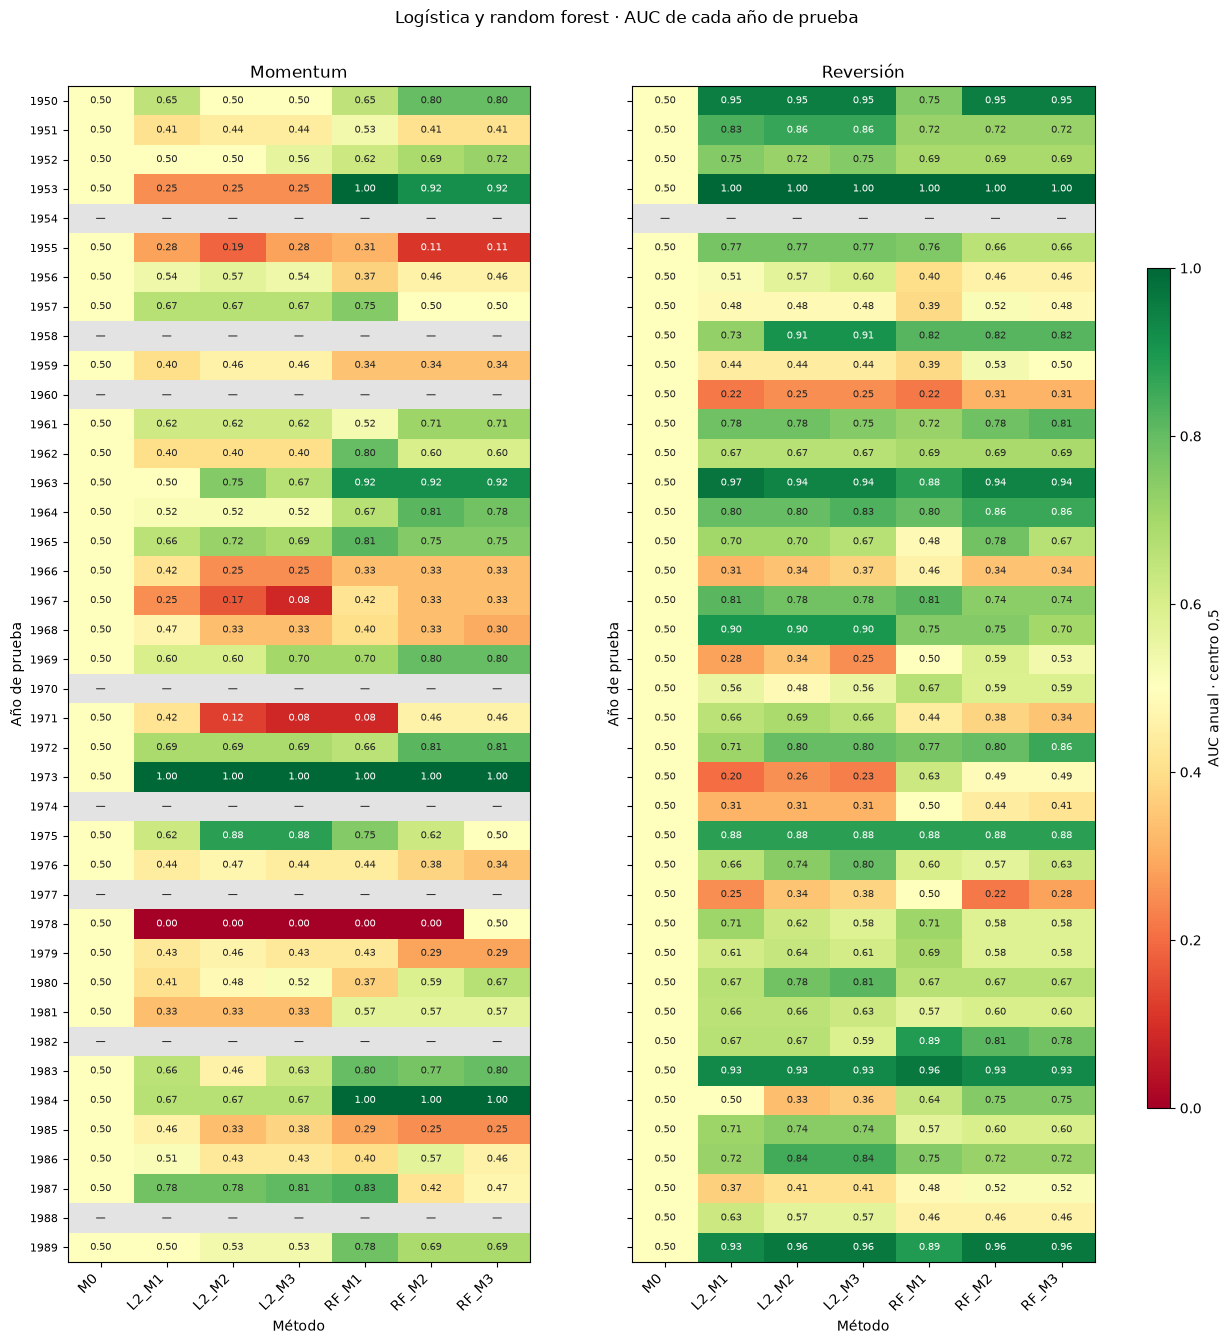

In [27]:
cmap_auc = plt.get_cmap('RdYlGn').copy()
cmap_auc.set_bad('#e3e3e3')
fig, axes = plt.subplots(1, 2, figsize=(13, 14), sharey=True)
for ax, (regla, titulo) in zip(axes, NOMBRES_REGLAS.items()):
    matriz = metricas_anuales.loc[metricas_anuales.strategy.eq(regla)].pivot(
        index='test_year', columns='model', values='auc').reindex(index=ANIOS, columns=list(MODELS))
    valores = matriz.to_numpy(dtype=float, na_value=np.nan)
    imagen = ax.imshow(np.ma.masked_invalid(valores), aspect='auto', cmap=cmap_auc,
        norm=TwoSlopeNorm(vmin=0, vcenter=.5, vmax=1), interpolation='nearest')
    ax.set_xticks(range(len(MODELS)), list(MODELS), rotation=45, ha='right')
    ax.set_yticks(range(len(ANIOS)), ANIOS)
    ax.tick_params(axis='y', labelsize=8)
    ax.set(title=titulo, xlabel='Método', ylabel='Año de prueba')
    for fila in range(len(ANIOS)):
        for columna in range(len(MODELS)):
            valor = valores[fila, columna]
            etiqueta = '—' if np.isnan(valor) else f'{valor:.2f}'
            color = 'white' if np.isfinite(valor) and (valor < .15 or valor > .85) else '#252525'
            ax.text(columna, fila, etiqueta, ha='center', va='center', fontsize=7, color=color)
fig.subplots_adjust(left=.07, right=.86, bottom=.09, top=.93, wspace=.22)
eje_color = fig.add_axes([.9, .2, .018, .6])
fig.colorbar(imagen, cax=eje_color, label='AUC anual · centro 0,5')
fig.suptitle('Logística y random forest · AUC de cada año de prueba', y=.985)
plt.show()

## 28. Cuántas operaciones sostienen cada resultado y cómo era el entorno

El primer gráfico cuenta las operaciones favorables y desfavorables. Las barras con una sola clase explican las rayas grises de la AUC. Con pocas operaciones, uno o dos cambios de orden pueden mover mucho la AUC: el tamaño de muestra acompaña siempre su interpretación.

El segundo gráfico resume **los doce meses de cada año objetivo**, usando las características que correspondían a sus decisiones:

- Meses bajistas: número de meses cuyo retorno previo de 24 meses era negativo.
- Media de volatilidad: promedio de los doce indicadores de volatilidad de 12 meses, anualizados.
- Distancia media al máximo: promedio de las doce distancias al máximo reciente de precios de 12 meses.

Estas medias describen el año una vez completo. El modelo recibía sus características mensuales preparadas con el pasado. La distancia al máximo pertenece al índice; las caídas de la cuenta de inversión se estudian en la evaluación económica.

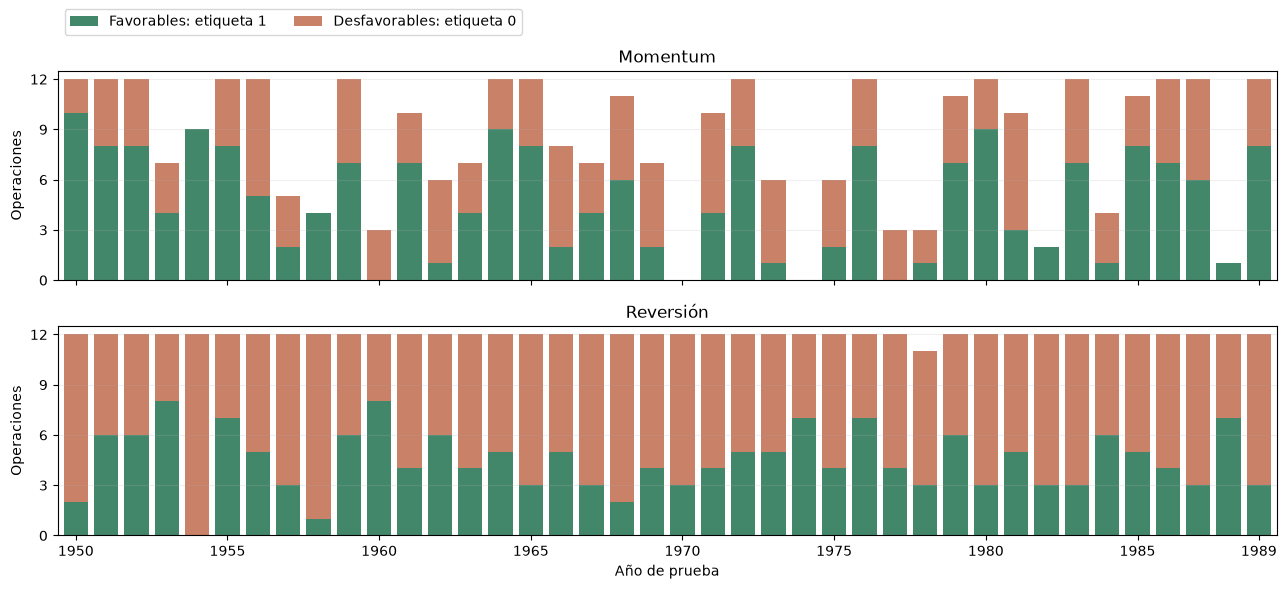

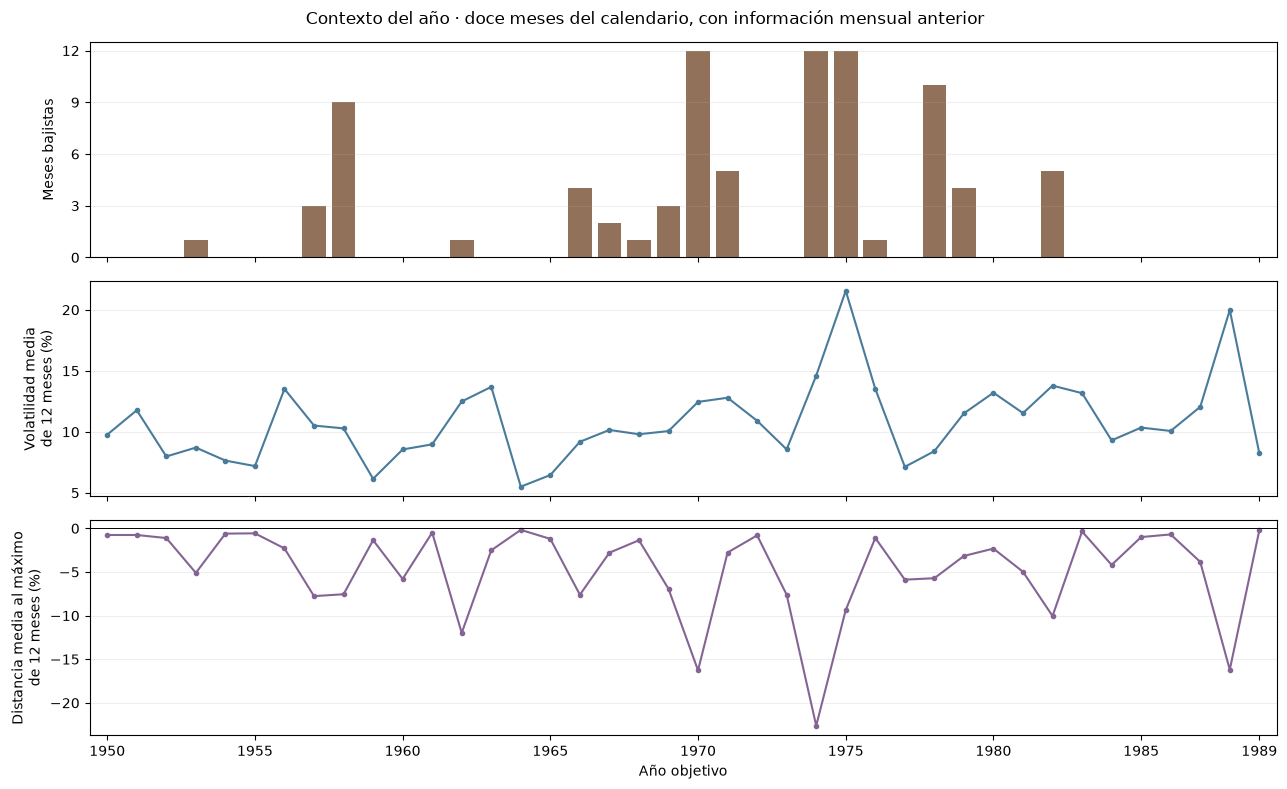

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, sharey=True)
for ax, (regla, titulo) in zip(axes, NOMBRES_REGLAS.items()):
    datos = operaciones_anuales.loc[operaciones_anuales.strategy.eq(regla)].set_index('test_year').reindex(ANIOS)
    positivas = datos.positive.to_numpy(dtype=int)
    negativas = datos.negative.to_numpy(dtype=int)
    ax.bar(ANIOS, positivas, color='#43876b', label='Favorables: etiqueta 1')
    ax.bar(ANIOS, negativas, bottom=positivas, color='#c98168', label='Desfavorables: etiqueta 0')
    ax.set(title=titulo, ylabel='Operaciones', ylim=(0, 12.5))
    ax.set_yticks([0, 3, 6, 9, 12])
    ax.grid(axis='y', alpha=.2)
axes[0].legend(loc='lower left', bbox_to_anchor=(0, 1.14), ncols=2)
axes[-1].set_xlabel('Año de prueba')
axes[-1].set_xlim(1949.4, 1989.6)
axes[-1].set_xticks([*range(1950, 1990, 5), 1989])
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
axes[0].bar(contexto_anual.test_year, contexto_anual.bear_months, color='#92715b')
axes[0].set(ylabel='Meses bajistas', ylim=(0, 12.5))
axes[0].set_yticks([0, 3, 6, 9, 12])
axes[1].plot(contexto_anual.test_year, 100*contexto_anual.mean_volatility_12m,
    marker='o', markersize=3, color='#497b9b')
axes[1].set_ylabel('Volatilidad media\nde 12 meses (%)')
axes[2].plot(contexto_anual.test_year, 100*contexto_anual.mean_drawdown_12m,
    marker='o', markersize=3, color='#846494')
axes[2].axhline(0, color='black', linewidth=.7)
axes[2].set(ylabel='Distancia media al máximo\nde 12 meses (%)', xlabel='Año objetivo')
for ax in axes:
    ax.grid(axis='y', alpha=.2)
    ax.set_xticks([*range(1950, 1990, 5), 1989])
    ax.set_xlim(1949.4, 1989.6)
fig.suptitle('Contexto del año · doce meses del calendario, con información mensual anterior')
fig.tight_layout()
plt.show()

## 29. Leer un año con sus cifras y separar descripción de decisión

Cambia `ANIO_A_REVISAR` para consultar un año. La primera tabla muestra el mercado completo y la segunda el contexto de las operaciones de cada regla. Un año puede contener varios entornos y momentum puede operar solo en parte de ellos.

La última tabla reúne las AUC y log-loss de los siete métodos. El estado explica por qué una AUC queda ausente. Las cifras se presentan redondeadas; se mantienen las métricas completas en las tablas leídas.

Este diagnóstico permite formular preguntas sobre por qué varía el comportamiento. Los cuarenta años, los criterios de estabilidad y las listas se conservan. Las asociaciones que observemos aquí son exploratorias y deberán declararse al planear nuevos candidatos. Los controles propios del bosque y los pasos posteriores siguen pendientes.

In [29]:
ANIO_A_REVISAR = 1950
if ANIO_A_REVISAR not in ANIOS:
    raise ValueError('Elige un año entre 1950 y 1989.')

mercado_vista = contexto_anual.loc[contexto_anual.test_year.eq(ANIO_A_REVISAR)].copy()
mercado_vista[['mean_volatility_12m', 'mean_drawdown_12m']] *= 100
print(f'{ANIO_A_REVISAR} · contexto de los doce meses del mercado')
display(mercado_vista.rename(columns={
    'test_year': 'Año', 'calendar_months': 'Meses de mercado', 'bear_months': 'Meses bajistas',
    'mean_volatility_12m': 'Volatilidad media (%)', 'mean_drawdown_12m': 'Distancia media al máximo (%)'}).round(3))

operaciones_vista = operaciones_anuales.loc[operaciones_anuales.test_year.eq(ANIO_A_REVISAR)].copy()
operaciones_vista[['active_mean_volatility_12m', 'active_mean_drawdown_12m']] *= 100
print('Contexto limitado a los meses con operación de cada regla')
display(operaciones_vista[['strategy', 'examples', 'positive', 'negative', 'active_bear_months',
    'active_mean_volatility_12m', 'active_mean_drawdown_12m']].rename(columns={
    'strategy': 'Regla', 'examples': 'Operaciones', 'positive': 'Favorables', 'negative': 'Desfavorables',
    'active_bear_months': 'Operaciones en entorno bajista',
    'active_mean_volatility_12m': 'Volatilidad media en señales (%)',
    'active_mean_drawdown_12m': 'Distancia media en señales (%)'}).round(3))

estados_auc = {'available': 'Calculable', 'single_class': 'Una sola clase',
    'no_examples': 'Sin operaciones', 'unavailable_predictions': 'Faltan predicciones'}
for regla, titulo in NOMBRES_REGLAS.items():
    vista = metricas_anuales.loc[metricas_anuales.test_year.eq(ANIO_A_REVISAR)
        & metricas_anuales.strategy.eq(regla)].set_index('model').reindex(list(MODELS))
    vista = vista[['examples', 'positive', 'negative', 'auc', 'log_loss', 'auc_status']].copy()
    vista['auc_status'] = vista.auc_status.map(estados_auc)
    print(f'{titulo} · métricas de los mismos ejemplos')
    display(vista.rename(columns={'examples': 'Operaciones', 'positive': 'Favorables',
        'negative': 'Desfavorables', 'auc': 'AUC', 'log_loss': 'Log-loss',
        'auc_status': 'Estado AUC'}).round(4))

1950 · contexto de los doce meses del mercado


,Año,Meses de mercado,Meses bajistas,Volatilidad media (%),Distancia media al máximo (%)
0,1950,12,0,9.768,-0.759


Contexto limitado a los meses con operación de cada regla


,Regla,Operaciones,Favorables,Desfavorables,Operaciones en entorno bajista,Volatilidad media en señales (%),Distancia media en señales (%)
0,momentum,12,10,2,0,9.768,-0.759
1,reversal,12,2,10,0,9.768,-0.759


Momentum · métricas de los mismos ejemplos


,Operaciones,Favorables,Desfavorables,AUC,Log-loss,Estado AUC
model,,,,,,
M0,12,10,2,0.50,0.5613,Calculable
L2_M1,12,10,2,0.65,0.5471,Calculable
L2_M2,12,10,2,0.50,0.5485,Calculable
L2_M3,12,10,2,0.50,0.5466,Calculable
RF_M1,12,10,2,0.65,0.4934,Calculable
RF_M2,12,10,2,0.80,0.5037,Calculable
RF_M3,12,10,2,0.80,0.5133,Calculable


Reversión · métricas de los mismos ejemplos


,Operaciones,Favorables,Desfavorables,AUC,Log-loss,Estado AUC
model,,,,,,
M0,12,2,10,0.50,0.5542,Calculable
L2_M1,12,2,10,0.95,0.4984,Calculable
L2_M2,12,2,10,0.95,0.4943,Calculable
L2_M3,12,2,10,0.95,0.4942,Calculable
RF_M1,12,2,10,0.75,0.4321,Calculable
RF_M2,12,2,10,0.95,0.3768,Calculable
RF_M3,12,2,10,0.95,0.3714,Calculable
